In [290]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Các thư viện đã được import thành công!")

Các thư viện đã được import thành công!


In [301]:
# Đọc dữ liệu
df_uni = pd.read_csv("../data/raw/dataset_uni.csv")
df_multi = pd.read_csv("../data/raw/dataset_multi.csv")

# Chuyển Date thành kiểu ngày tháng
df_uni["Date"] = pd.to_datetime(df_uni["Date"])
df_multi["Date"] = pd.to_datetime(df_multi["Date"])

# Sắp xếp dữ liệu theo thời gian
df_uni = df_uni.sort_values("Date").reset_index(drop=True)
df_multi = df_multi.sort_values("Date").reset_index(drop=True)

# Kiểm tra dữ liệu
print("Univariate:", df_uni.shape)
print("Multivariate:", df_multi.shape)

display(df_uni.head())
display(df_multi.head())

Univariate: (4215, 2)
Multivariate: (4215, 8)


,Date,wti
0,2006-10-16,59.91
1,2006-10-17,58.91
2,2006-10-18,57.66
3,2006-10-19,58.55
4,2006-10-20,57.35


,Date,wti,GP,coal,TB,LTY,EPI,SRV
0,2006-10-16,59.91,5.13,49.049999,4.96,4.6,42.85,0.000002
1,2006-10-17,58.91,6.26,49.250000,4.96,4.6,143.06,0.000002
2,2006-10-18,57.66,6.07,49.400002,4.96,4.6,28.55,0.000002
3,2006-10-19,58.55,6.77,48.750000,4.97,4.6,20.71,0.000002
4,2006-10-20,57.35,6.88,49.000000,4.96,4.6,88.78,0.000002


In [302]:

import pandas as pd
import numpy as np

# Đọc dữ liệu đa biến ban đầu
df_clean = pd.read_csv("../data/raw/dataset_multi.csv")

df_clean["Date"] = pd.to_datetime(df_clean["Date"])

df_clean = df_clean.sort_values("Date").reset_index(drop=True)

# Chỉ giữ những biến cần thiết
df_clean = df_clean[
    ["Date", "wti", "GP", "coal", "EPI"]
].copy()


# =====================================
# 1. XỬ LÝ TB TỪ DỮ LIỆU GỐC
# =====================================

tb_raw = pd.read_excel(
    "../data/raw/dataset.xlsx",
    sheet_name="Treasury bill rate "
)

tb_raw["date"] = pd.to_datetime(tb_raw["date"])

tb_raw = tb_raw.rename(columns={"date": "Date"})

df_clean = df_clean.merge(
    tb_raw[["Date", "TB"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

# Chỉ sử dụng giá trị đã quan sát trong quá khứ
df_clean["TB"] = df_clean["TB"].ffill()


# =====================================
# 2. XỬ LÝ SRV TỪ DỮ LIỆU GỐC
# =====================================

srv_raw = pd.read_excel(
    "../data/raw/dataset.xlsx",
    sheet_name="Stock return variance "
)

srv_raw["date"] = pd.to_datetime(srv_raw["date"])

srv_raw = srv_raw.rename(columns={"date": "Date"})

df_clean = df_clean.merge(
    srv_raw[["Date", "SRV"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

# Không bfill SRV.
# Chỉ điền bằng giá trị đã xuất hiện trước đó.
df_clean["SRV"] = df_clean["SRV"].ffill()


# =====================================
# 3. LOẠI GIAI ĐOẠN CHƯA CÓ SRV
# =====================================

first_srv_date = df_clean.loc[
    df_clean["SRV"].notna(), "Date"
].min()

df_clean = df_clean[
    df_clean["Date"] >= first_srv_date
].copy().reset_index(drop=True)


# =====================================
# 4. TẠO LAG FEATURES
# =====================================

features = ["wti", "GP", "coal", "TB", "EPI", "SRV"]

lags = [1, 2, 3, 5, 10, 20]

for feature in features:
    for lag in lags:
        df_clean[f"{feature}_Lag{lag}"] = (
            df_clean[feature].shift(lag)
        )

# Tạo mục tiêu
df_clean["WTI_Change"] = (
    df_clean["wti"] - df_clean["wti_Lag1"]
)

# Loại 20 dòng đầu do lag lớn nhất là 20
df_clean = (
    df_clean.iloc[20:]
    .reset_index(drop=True)
)


# =====================================
# 5. KIỂM TRA KẾT QUẢ
# =====================================

print("Kích thước dữ liệu:", df_clean.shape)

print("Ngày bắt đầu:", df_clean["Date"].min())
print("Ngày kết thúc:", df_clean["Date"].max())

print("Số giá trị thiếu TB:", df_clean["TB"].isna().sum())
print("Số giá trị thiếu SRV:", df_clean["SRV"].isna().sum())

print("\n20 dòng đầu:")
display(df_clean.head(20))


Kích thước dữ liệu: (2473, 44)
Ngày bắt đầu: 2013-09-16 00:00:00
Ngày kết thúc: 2023-07-24 00:00:00
Số giá trị thiếu TB: 0
Số giá trị thiếu SRV: 0

20 dòng đầu:


,Date,wti,GP,coal,EPI,TB,SRV,wti_Lag1,wti_Lag2,wti_Lag3,...,EPI_Lag5,EPI_Lag10,EPI_Lag20,SRV_Lag1,SRV_Lag2,SRV_Lag3,SRV_Lag5,SRV_Lag10,SRV_Lag20,WTI_Change
0,2013-09-16,106.54,3.64,76.900002,149.94,0.02,6.078676e-06,108.31,108.72,107.65,...,59.96,91.16,76.50,1.386240e-06,2.162643e-06,1.751830e-06,1.864801e-05,1.906504e-06,2.066540e-06,-1.77
1,2013-09-17,105.36,3.77,77.699997,127.79,0.01,3.341146e-06,106.54,108.31,108.72,...,53.00,168.05,136.62,6.078676e-06,1.386240e-06,2.162643e-06,1.010329e-05,1.906504e-06,6.605338e-06,-1.18
2,2013-09-18,108.23,3.72,78.150002,84.39,0.01,2.763343e-05,105.36,106.54,108.31,...,96.02,133.57,111.56,3.341146e-06,6.078676e-06,1.386240e-06,1.751830e-06,1.232666e-05,2.743606e-06,2.87
3,2013-09-19,106.26,3.73,78.000000,87.37,0.01,6.417766e-07,108.23,105.36,106.54,...,59.84,121.68,96.17,2.763343e-05,3.341146e-06,6.078676e-06,2.162643e-06,2.757501e-07,6.337054e-06,-1.97
4,2013-09-20,104.70,3.68,77.699997,160.51,0.01,9.895024e-06,106.26,108.23,105.36,...,39.94,174.48,89.29,6.417766e-07,2.763343e-05,3.341146e-06,1.386240e-06,5.576890e-10,1.389299e-05,-1.56
5,2013-09-23,103.62,3.66,78.300003,105.52,0.02,4.221073e-06,104.70,106.26,108.23,...,149.94,59.96,45.99,9.895024e-06,6.417766e-07,2.763343e-05,6.078676e-06,1.864801e-05,2.926771e-06,-1.08
6,2013-09-24,103.22,3.59,78.300003,127.69,0.02,1.275572e-06,103.62,104.70,106.26,...,127.79,53.00,124.03,4.221073e-06,9.895024e-06,6.417766e-07,3.341146e-06,1.010329e-05,3.090430e-06,-0.40
7,2013-09-25,102.68,3.52,78.449997,134.20,0.02,1.419342e-06,103.22,103.62,104.70,...,84.39,96.02,86.16,1.275572e-06,4.221073e-06,9.895024e-06,2.763343e-05,1.751830e-06,4.829371e-05,-0.54
8,2013-09-26,103.10,3.49,78.449997,83.62,0.00,2.283312e-06,102.68,103.22,103.62,...,87.37,59.84,64.04,1.419342e-06,1.275572e-06,4.221073e-06,6.417766e-07,2.162643e-06,1.420044e-06,0.42
9,2013-09-27,102.86,3.51,78.300003,91.83,0.02,3.142932e-06,103.10,102.68,103.22,...,160.51,39.94,87.64,2.283312e-06,1.419342e-06,1.275572e-06,9.895024e-06,1.386240e-06,7.256254e-07,-0.24


In [303]:
# Sử dụng dữ liệu đã xử lý sạch từ df_clean
data_multi = df_clean.copy()

print("Kích thước:", data_multi.shape)
print("Các cột:", data_multi.columns.tolist())

display(data_multi.head())

Kích thước: (2473, 44)
Các cột: ['Date', 'wti', 'GP', 'coal', 'EPI', 'TB', 'SRV', 'wti_Lag1', 'wti_Lag2', 'wti_Lag3', 'wti_Lag5', 'wti_Lag10', 'wti_Lag20', 'GP_Lag1', 'GP_Lag2', 'GP_Lag3', 'GP_Lag5', 'GP_Lag10', 'GP_Lag20', 'coal_Lag1', 'coal_Lag2', 'coal_Lag3', 'coal_Lag5', 'coal_Lag10', 'coal_Lag20', 'TB_Lag1', 'TB_Lag2', 'TB_Lag3', 'TB_Lag5', 'TB_Lag10', 'TB_Lag20', 'EPI_Lag1', 'EPI_Lag2', 'EPI_Lag3', 'EPI_Lag5', 'EPI_Lag10', 'EPI_Lag20', 'SRV_Lag1', 'SRV_Lag2', 'SRV_Lag3', 'SRV_Lag5', 'SRV_Lag10', 'SRV_Lag20', 'WTI_Change']


,Date,wti,GP,coal,EPI,TB,SRV,wti_Lag1,wti_Lag2,wti_Lag3,...,EPI_Lag5,EPI_Lag10,EPI_Lag20,SRV_Lag1,SRV_Lag2,SRV_Lag3,SRV_Lag5,SRV_Lag10,SRV_Lag20,WTI_Change
0,2013-09-16,106.54,3.64,76.900002,149.94,0.02,6.078676e-06,108.31,108.72,107.65,...,59.96,91.16,76.50,1.386240e-06,0.000002,0.000002,0.000019,1.906504e-06,0.000002,-1.77
1,2013-09-17,105.36,3.77,77.699997,127.79,0.01,3.341146e-06,106.54,108.31,108.72,...,53.00,168.05,136.62,6.078676e-06,0.000001,0.000002,0.000010,1.906504e-06,0.000007,-1.18
2,2013-09-18,108.23,3.72,78.150002,84.39,0.01,2.763343e-05,105.36,106.54,108.31,...,96.02,133.57,111.56,3.341146e-06,0.000006,0.000001,0.000002,1.232666e-05,0.000003,2.87
3,2013-09-19,106.26,3.73,78.000000,87.37,0.01,6.417766e-07,108.23,105.36,106.54,...,59.84,121.68,96.17,2.763343e-05,0.000003,0.000006,0.000002,2.757501e-07,0.000006,-1.97
4,2013-09-20,104.70,3.68,77.699997,160.51,0.01,9.895024e-06,106.26,108.23,105.36,...,39.94,174.48,89.29,6.417766e-07,0.000028,0.000003,0.000001,5.576890e-10,0.000014,-1.56


In [304]:
# Sao chép dữ liệu
data_multi = df_multi[
    ["Date", "wti", "GP", "coal", "TB", "EPI", "SRV"]
].copy()

# Các biến đầu vào
features = ["wti", "GP", "coal", "TB", "EPI", "SRV"]

# Các mốc Lag
lags = [1, 2, 3, 5, 10, 20]

# Tạo Lag Features
for feature in features:
    for lag in lags:
        data_multi[f"{feature}_Lag{lag}"] = (
            data_multi[feature].shift(lag)
        )

# Kiểm tra kết quả
print("Kích thước:", data_multi.shape)
display(data_multi.head(25))

Kích thước: (4215, 43)


,Date,wti,GP,coal,TB,EPI,SRV,wti_Lag1,wti_Lag2,wti_Lag3,...,EPI_Lag3,EPI_Lag5,EPI_Lag10,EPI_Lag20,SRV_Lag1,SRV_Lag2,SRV_Lag3,SRV_Lag5,SRV_Lag10,SRV_Lag20
0,2006-10-16,59.91,5.13,49.049999,4.96,42.85,0.000002,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2006-10-17,58.91,6.26,49.250000,4.96,143.06,0.000002,59.91,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000002,NaN,NaN,NaN,NaN,NaN
2,2006-10-18,57.66,6.07,49.400002,4.96,28.55,0.000002,58.91,59.91,NaN,...,NaN,NaN,NaN,NaN,0.000002,0.000002,NaN,NaN,NaN,NaN
3,2006-10-19,58.55,6.77,48.750000,4.97,20.71,0.000002,57.66,58.91,59.91,...,42.85,NaN,NaN,NaN,0.000002,0.000002,0.000002,NaN,NaN,NaN
4,2006-10-20,57.35,6.88,49.000000,4.96,88.78,0.000002,58.55,57.66,58.91,...,143.06,NaN,NaN,NaN,0.000002,0.000002,0.000002,NaN,NaN,NaN
5,2006-10-23,56.74,7.29,50.299999,4.99,40.93,0.000002,57.35,58.55,57.66,...,28.55,42.85,NaN,NaN,0.000002,0.000002,0.000002,0.000002,NaN,NaN
6,2006-10-24,57.55,7.13,50.500000,5.00,32.62,0.000002,56.74,57.35,58.55,...,20.71,143.06,NaN,NaN,0.000002,0.000002,0.000002,0.000002,NaN,NaN
7,2006-10-25,59.09,7.20,49.500000,4.99,50.21,0.000002,57.55,56.74,57.35,...,88.78,28.55,NaN,NaN,0.000002,0.000002,0.000002,0.000002,NaN,NaN
8,2006-10-26,60.27,7.91,49.500000,4.99,46.58,0.000002,59.09,57.55,56.74,...,40.93,20.71,NaN,NaN,0.000002,0.000002,0.000002,0.000002,NaN,NaN
9,2006-10-27,60.75,7.41,50.799999,4.98,54.44,0.000002,60.27,59.09,57.55,...,32.62,88.78,NaN,NaN,0.000002,0.000002,0.000002,0.000002,NaN,NaN


In [305]:
# Danh sách các biến đầu vào
features_multi = [
    col for col in data_multi.columns
    if "_Lag" in col
]

# Biến mục tiêu
target = "wti"

print("Số lượng biến đầu vào:", len(features_multi))
print("Các biến đầu vào:")
print(features_multi)

Số lượng biến đầu vào: 36
Các biến đầu vào:
['wti_Lag1', 'wti_Lag2', 'wti_Lag3', 'wti_Lag5', 'wti_Lag10', 'wti_Lag20', 'GP_Lag1', 'GP_Lag2', 'GP_Lag3', 'GP_Lag5', 'GP_Lag10', 'GP_Lag20', 'coal_Lag1', 'coal_Lag2', 'coal_Lag3', 'coal_Lag5', 'coal_Lag10', 'coal_Lag20', 'TB_Lag1', 'TB_Lag2', 'TB_Lag3', 'TB_Lag5', 'TB_Lag10', 'TB_Lag20', 'EPI_Lag1', 'EPI_Lag2', 'EPI_Lag3', 'EPI_Lag5', 'EPI_Lag10', 'EPI_Lag20', 'SRV_Lag1', 'SRV_Lag2', 'SRV_Lag3', 'SRV_Lag5', 'SRV_Lag10', 'SRV_Lag20']


In [306]:
# Sử dụng dữ liệu đã có Lag và WTI_Change
data_multi_model = data_multi.copy()

data_multi_model = (
    data_multi_model.reset_index(drop=True)
)

# Danh sách Features
features_multi = [
    col for col in data_multi_model.columns
    if "_Lag" in col
]

# Biến mục tiêu
target = "wti"

print("Multivariate:", data_multi_model.shape)
print("Số Features:", len(features_multi))
print("Có WTI_Change:", "WTI_Change" in data_multi_model.columns)

print("Ngày bắt đầu:", data_multi_model["Date"].min())
print("Ngày kết thúc:", data_multi_model["Date"].max())

Multivariate: (4215, 43)
Số Features: 36
Có WTI_Change: False
Ngày bắt đầu: 2006-10-16 00:00:00
Ngày kết thúc: 2023-07-24 00:00:00


In [307]:
print("===== UNIVARIATE =====")
print("Kích thước:", data_uni_model.shape)
print("Số biến đầu vào:", len(features_uni))

print("\n===== MULTIVARIATE =====")
print("Kích thước:", data_multi_model.shape)
print("Số biến đầu vào:", len(features_multi))

print("\n===== KIỂM TRA NGÀY =====")
print("Ngày bắt đầu Uni:", data_uni_model["Date"].min())
print("Ngày bắt đầu Multi:", data_multi_model["Date"].min())

print("Ngày kết thúc Uni:", data_uni_model["Date"].max())
print("Ngày kết thúc Multi:", data_multi_model["Date"].max())

print("\nCùng ngày theo từng dòng:",
      data_uni_model["Date"].equals(data_multi_model["Date"]))

print("\nMissing WTI Uni:",
      data_uni_model["wti"].isnull().sum())

print("Missing WTI Multi:",
      data_multi_model["wti"].isnull().sum())

===== UNIVARIATE =====
Kích thước: (4195, 9)
Số biến đầu vào: 6

===== MULTIVARIATE =====
Kích thước: (4215, 43)
Số biến đầu vào: 36

===== KIỂM TRA NGÀY =====
Ngày bắt đầu Uni: 2006-11-13 00:00:00
Ngày bắt đầu Multi: 2006-10-16 00:00:00
Ngày kết thúc Uni: 2023-07-24 00:00:00
Ngày kết thúc Multi: 2023-07-24 00:00:00

Cùng ngày theo từng dòng: False

Missing WTI Uni: 0
Missing WTI Multi: 0


In [308]:
# Tách biến đầu vào X và biến mục tiêu y
X_uni = data_uni_model[features_uni]
y_uni = data_uni_model["wti"]

# Chia theo thời gian: 80% đầu để Train, 20% cuối để Test
split_uni = int(len(data_uni_model) * 0.8)

X_train_uni = X_uni.iloc[:split_uni]
X_test_uni = X_uni.iloc[split_uni:]

y_train_uni = y_uni.iloc[:split_uni]
y_test_uni = y_uni.iloc[split_uni:]

# Kiểm tra
print("Train:", X_train_uni.shape)
print("Test:", X_test_uni.shape)

print("Ngày bắt đầu Test:",
      data_uni_model["Date"].iloc[split_uni])

Train: (3356, 6)
Test: (839, 6)
Ngày bắt đầu Test: 2020-03-20 00:00:00


In [310]:
# Tách X và các biến mục tiêu
X_multi = data_multi_model[features_multi]

y_multi = data_multi_model["wti"]

y_change_multi = data_multi_model["WTI_Change"]

# Giữ nguyên ngày bắt đầu Test
split_date = pd.Timestamp("2020-03-20")

train_mask = data_multi_model["Date"] < split_date
test_mask = data_multi_model["Date"] >= split_date

# Chia X
X_train_multi = X_multi.loc[train_mask].copy()
X_test_multi = X_multi.loc[test_mask].copy()

# Chia mục tiêu giá WTI
y_train_multi = y_multi.loc[train_mask].copy()
y_test_multi = y_multi.loc[test_mask].copy()

# Chia mục tiêu mức thay đổi WTI
y_train_change_multi = (
    y_change_multi.loc[train_mask].copy()
)

y_test_change_multi = (
    y_change_multi.loc[test_mask].copy()
)

# Số dòng Train, dùng cho các cell phía sau
split_multi = len(X_train_multi)

print("Train:", X_train_multi.shape)
print("Test:", X_test_multi.shape)

print("Số dòng Train:", len(X_train_multi))
print("Số dòng Test:", len(X_test_multi))

print(
    "Ngày bắt đầu Test:",
    data_multi_model.loc[test_mask, "Date"].min()
)

print(
    "Ngày kết thúc Test:",
    data_multi_model.loc[test_mask, "Date"].max()
)

KeyError: 'WTI_Change'

In [300]:
print("===== UNIVARIATE =====")
print("X_train:", X_train_uni.shape)
print("X_test:", X_test_uni.shape)
print("y_train:", y_train_uni.shape)
print("y_test:", y_test_uni.shape)

print("\n===== MULTIVARIATE =====")
print("X_train:", X_train_multi.shape)
print("X_test:", X_test_multi.shape)
print("y_train:", y_train_multi.shape)
print("y_test:", y_test_multi.shape)

===== UNIVARIATE =====
X_train: (3356, 6)
X_test: (839, 6)
y_train: (3356,)
y_test: (839,)

===== MULTIVARIATE =====
X_train: (3356, 36)
X_test: (839, 36)
y_train: (3356,)
y_test: (839,)


In [158]:
# Kiểm tra số lượng NaN trong tập Train và Test
print("===== UNIVARIATE =====")
print("Train:", X_train_uni.isnull().sum().sum())
print("Test:", X_test_uni.isnull().sum().sum())

print("\n===== MULTIVARIATE =====")
print("Train:", X_train_multi.isnull().sum().sum())
print("Test:", X_test_multi.isnull().sum().sum())

# Xác định những cột có NaN
print("\nCác cột Multivariate có NaN:")
print(X_train_multi.columns[X_train_multi.isnull().any()].tolist())

===== UNIVARIATE =====
Train: 0
Test: 0

===== MULTIVARIATE =====
Train: 108
Test: 156

Các cột Multivariate có NaN:
['GP_Lag1', 'GP_Lag2', 'GP_Lag3', 'GP_Lag5', 'GP_Lag10', 'GP_Lag20', 'coal_Lag1', 'coal_Lag2', 'coal_Lag3', 'coal_Lag5', 'coal_Lag10', 'coal_Lag20']


In [159]:
# Cấu hình XGBoost
xgb_params = {
    "n_estimators": 500,
    "learning_rate": 0.03,
    "max_depth": 4,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}

# Tạo mô hình Univariate
model_uni = XGBRegressor(**xgb_params)

# Tạo mô hình Multivariate
model_multi = XGBRegressor(**xgb_params)

print("Đã khởi tạo hai mô hình XGBoost!")

Đã khởi tạo hai mô hình XGBoost!


In [160]:
model_uni.fit(X_train_uni, y_train_uni)

print("Đã huấn luyện xong mô hình Univariate!")

Đã huấn luyện xong mô hình Univariate!


In [161]:
model_multi.fit(X_train_multi, y_train_multi)

print("Đã huấn luyện xong mô hình Multivariate!")

Đã huấn luyện xong mô hình Multivariate!


In [162]:
# Dự báo Univariate
y_pred_uni = model_uni.predict(X_test_uni)

# Dự báo Multivariate
y_pred_multi = model_multi.predict(X_test_multi)

print("Đã dự báo xong!")

print("5 giá trị thực tế:")
print(y_test_uni.head().values)

print("\n5 giá trị dự báo Univariate:")
print(y_pred_uni[:5])

print("\n5 giá trị dự báo Multivariate:")
print(y_pred_multi[:5])

Đã dự báo xong!
5 giá trị thực tế:
[19.48 23.33 21.03 20.75 16.6 ]

5 giá trị dự báo Univariate:
[25.52568  27.925764 28.555891 28.909693 29.188248]

5 giá trị dự báo Multivariate:
[27.785322 26.472008 25.56184  25.912771 27.20664 ]


In [163]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import numpy as np

def evaluate_model(y_true, y_pred, previous_price):

    # MAE
    mae = mean_absolute_error(y_true, y_pred)

    # RMSE
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # R-squared
    r2 = r2_score(y_true, y_pred)

    # Directional Accuracy
    actual_direction = np.sign(
        np.asarray(y_true) - np.asarray(previous_price)
    )

    predicted_direction = np.sign(
        np.asarray(y_pred) - np.asarray(previous_price)
    )

    da = np.mean(
        actual_direction == predicted_direction
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "DA (%)": da
    }

In [164]:
# Giá WTI của phiên trước tại thời điểm dự báo
previous_uni = X_test_uni["WTI_Lag1"]

previous_multi = X_test_multi["wti_Lag1"]

# Đánh giá hai mô hình
results_uni = evaluate_model(
    y_test_uni,
    y_pred_uni,
    previous_uni
)

results_multi = evaluate_model(
    y_test_multi,
    y_pred_multi,
    previous_multi
)

# Tạo bảng so sánh
results = pd.DataFrame(
    [results_uni, results_multi],
    index=["Univariate", "Multivariate"]
)

display(results.round(4))

,MAE,RMSE,R2,DA (%)
Univariate,1.9356,3.7773,0.9741,50.4172
Multivariate,2.1877,3.7894,0.9739,46.6031


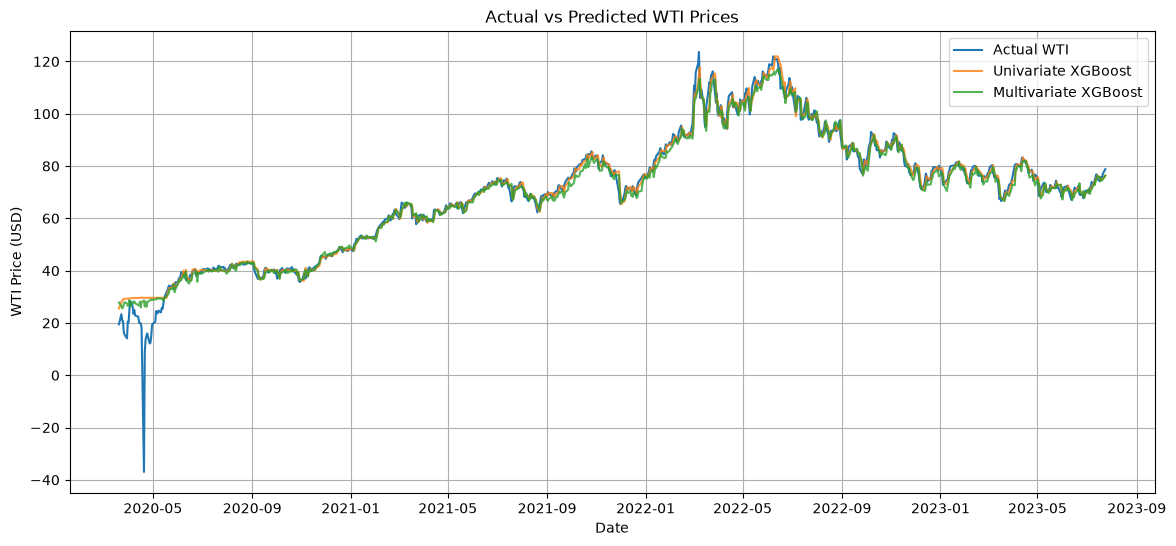

In [165]:
plt.figure(figsize=(14, 6))

plt.plot(
    data_uni_model["Date"].iloc[split_uni:],
    y_test_uni.values,
    label="Actual WTI",
    linewidth=1.5
)

plt.plot(
    data_uni_model["Date"].iloc[split_uni:],
    y_pred_uni,
    label="Univariate XGBoost",
    alpha=0.8
)

plt.plot(
    data_multi_model["Date"].iloc[split_multi:],
    y_pred_multi,
    label="Multivariate XGBoost",
    alpha=0.8
)

plt.title("Actual vs Predicted WTI Prices")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [166]:
# Tính mức thay đổi giá thực tế
actual_change = (
    np.asarray(y_test_uni)
    - np.asarray(X_test_uni["WTI_Lag1"])
)

# Tính mức thay đổi giá dự báo
uni_change = (
    y_pred_uni
    - np.asarray(X_test_uni["WTI_Lag1"])
)

multi_change = (
    y_pred_multi
    - np.asarray(X_test_multi["wti_Lag1"])
)

# Tạo bảng so sánh
comparison = pd.DataFrame({
    "Actual Change": actual_change,
    "Uni Predicted Change": uni_change,
    "Multi Predicted Change": multi_change
})

display(comparison.head(15).round(3))

,Actual Change,Uni Predicted Change,Multi Predicted Change
0,-5.61,0.436,2.695
1,3.85,8.446,6.992
2,-2.30,5.226,2.232
3,-0.28,7.880,4.883
4,-4.15,8.438,6.457
5,-1.12,12.624,11.350
6,-1.38,13.804,11.938
7,6.41,15.142,12.432
8,-0.23,8.774,6.176
9,4.90,9.040,8.405


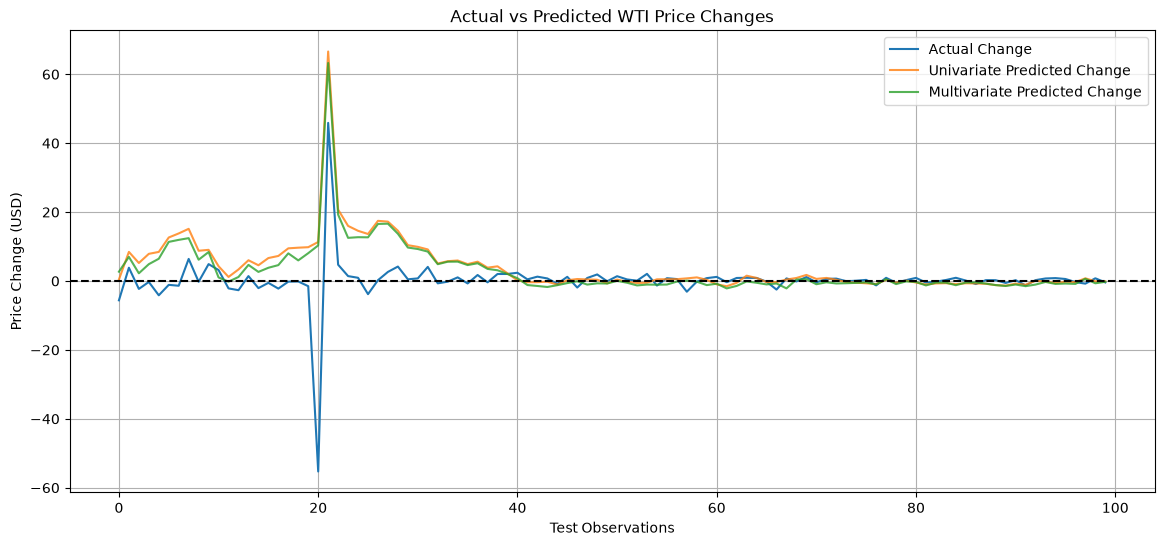

In [167]:
plt.figure(figsize=(14, 6))

plt.plot(
    actual_change[:100],
    label="Actual Change",
    linewidth=1.5
)

plt.plot(
    uni_change[:100],
    label="Univariate Predicted Change",
    alpha=0.8
)

plt.plot(
    multi_change[:100],
    label="Multivariate Predicted Change",
    alpha=0.8
)

plt.axhline(y=0, linestyle="--", color="black")

plt.title("Actual vs Predicted WTI Price Changes")
plt.xlabel("Test Observations")
plt.ylabel("Price Change (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [168]:
# Tạo mục tiêu là mức thay đổi giá WTI
data_uni_model["WTI_Change"] = (
    data_uni_model["wti"] -
    data_uni_model["WTI_Lag1"]
)

data_multi_model["WTI_Change"] = (
    data_multi_model["wti"] -
    data_multi_model["wti_Lag1"]
)

# Kiểm tra
display(
    data_uni_model[
        ["Date", "wti", "WTI_Lag1", "WTI_Change"]
    ].head(10)
)

,Date,wti,WTI_Lag1,WTI_Change
0,2006-11-13,58.59,59.66,-1.07
1,2006-11-14,58.28,58.59,-0.31
2,2006-11-15,58.79,58.28,0.51
3,2006-11-16,56.23,58.79,-2.56
4,2006-11-17,55.90,56.23,-0.33
5,2006-11-20,56.42,55.90,0.52
6,2006-11-21,58.01,56.42,1.59
7,2006-11-22,57.28,58.01,-0.73
8,2006-11-27,60.30,57.28,3.02
9,2006-11-28,60.97,60.30,0.67


In [169]:
# Biến mục tiêu mới
y_change_uni = data_uni_model["WTI_Change"]
y_change_multi = data_multi_model["WTI_Change"]

# Chia Univariate
y_train_change_uni = y_change_uni.iloc[:split_uni]
y_test_change_uni = y_change_uni.iloc[split_uni:]

# Chia Multivariate
y_train_change_multi = y_change_multi.iloc[:split_multi]
y_test_change_multi = y_change_multi.iloc[split_multi:]

print("Univariate:", y_train_change_uni.shape,
      y_test_change_uni.shape)

print("Multivariate:", y_train_change_multi.shape,
      y_test_change_multi.shape)

Univariate: (3356,) (839,)
Multivariate: (3356,) (839,)


In [170]:
# Khởi tạo mô hình
model_change_uni = XGBRegressor(**xgb_params)
model_change_multi = XGBRegressor(**xgb_params)

# Huấn luyện Univariate
model_change_uni.fit(
    X_train_uni,
    y_train_change_uni
)

# Huấn luyện Multivariate
model_change_multi.fit(
    X_train_multi,
    y_train_change_multi
)

print("Đã huấn luyện xong hai mô hình dự báo mức thay đổi!")

Đã huấn luyện xong hai mô hình dự báo mức thay đổi!


In [171]:
# Dự báo mức thay đổi
pred_change_uni = model_change_uni.predict(X_test_uni)

pred_change_multi = model_change_multi.predict(X_test_multi)

# Lấy giá WTI của phiên trước
previous_price = X_test_uni["WTI_Lag1"].values

# Khôi phục giá WTI dự báo
pred_price_change_uni = previous_price + pred_change_uni

pred_price_change_multi = previous_price + pred_change_multi

print("5 mức thay đổi dự báo Univariate:")
print(pred_change_uni[:5])

print("\n5 mức thay đổi dự báo Multivariate:")
print(pred_change_multi[:5])

print("\n5 giá WTI dự báo Univariate:")
print(pred_price_change_uni[:5])

print("\n5 giá WTI dự báo Multivariate:")
print(pred_price_change_multi[:5])

5 mức thay đổi dự báo Univariate:
[1.1791618  0.39018205 0.7814448  0.5430044  0.63247204]

5 mức thay đổi dự báo Multivariate:
[ 1.4168799  -0.04523155  0.7461931   0.86349607  1.762884  ]

5 giá WTI dự báo Univariate:
[26.26916179 19.87018205 24.11144479 21.57300439 21.38247204]

5 giá WTI dự báo Multivariate:
[26.50687989 19.43476845 24.07619311 21.89349607 22.51288402]


In [172]:
# Đánh giá Univariate Change Model
results_change_uni = evaluate_model(
    y_test_uni,
    pred_price_change_uni,
    X_test_uni["WTI_Lag1"]
)

# Đánh giá Multivariate Change Model
results_change_multi = evaluate_model(
    y_test_multi,
    pred_price_change_multi,
    X_test_multi["wti_Lag1"]
)

# Tạo bảng kết quả
results_e3 = pd.DataFrame(
    [results_change_uni, results_change_multi],
    index=[
        "Univariate Change",
        "Multivariate Change"
    ]
)

display(results_e3.round(4))

,MAE,RMSE,R2,DA (%)
Univariate Change,1.5856,3.2267,0.9811,48.8677
Multivariate Change,1.8501,3.4439,0.9785,46.4839


In [173]:
all_results = pd.DataFrame(
    [
        results_uni,
        results_multi,
        results_change_uni,
        results_change_multi
    ],
    index=[
        "E1 - Univariate XGBoost",
        "E2 - Multivariate XGBoost",
        "E3 - Univariate Change",
        "E3 - Multivariate Change"
    ]
)

display(all_results.round(4))

,MAE,RMSE,R2,DA (%)
E1 - Univariate XGBoost,1.9356,3.7773,0.9741,50.4172
E2 - Multivariate XGBoost,2.1877,3.7894,0.9739,46.6031
E3 - Univariate Change,1.5856,3.2267,0.9811,48.8677
E3 - Multivariate Change,1.8501,3.4439,0.9785,46.4839


In [174]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [175]:
# Lấy tối đa 500 quan sát từ tập Test
X_shap = X_test_multi.sample(
    n=min(500, len(X_test_multi)),
    random_state=42
)

# Tạo SHAP Explainer
explainer = shap.TreeExplainer(model_change_multi)

# Tính SHAP values
shap_values = explainer(X_shap)

print("Đã tính SHAP values!")
print("Kích thước:", shap_values.values.shape)

Đã tính SHAP values!
Kích thước: (500, 36)


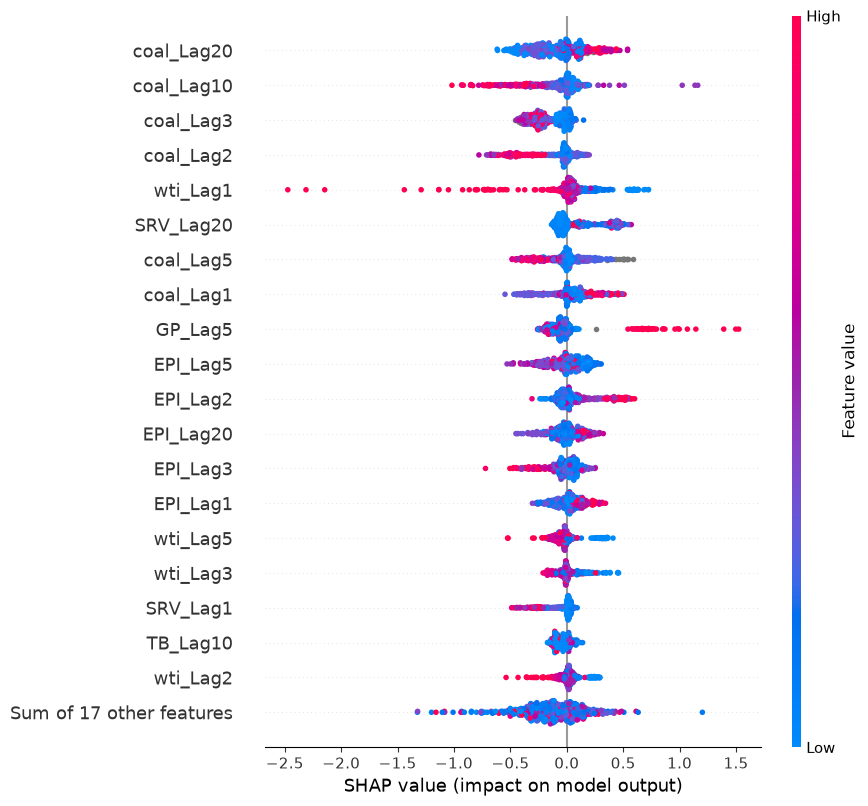

In [176]:
shap.plots.beeswarm(
    shap_values,
    max_display=20
)

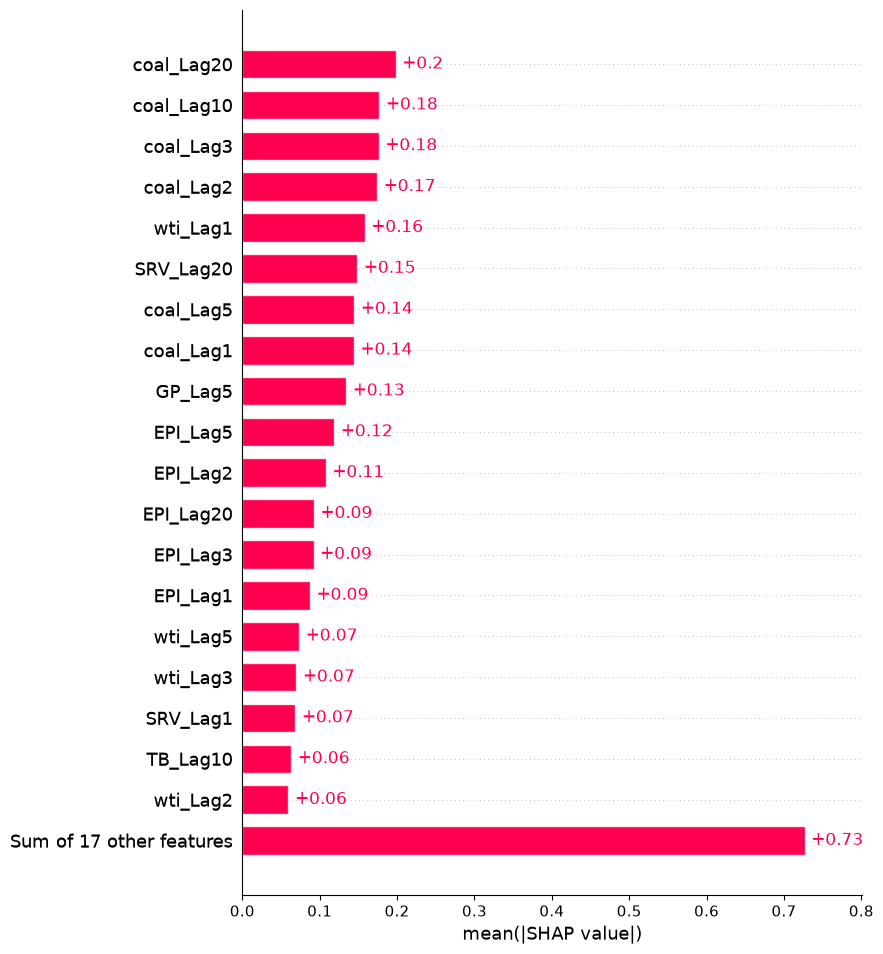

In [177]:
shap.plots.bar(
    shap_values,
    max_display=20
)

In [178]:
# Tạo bảng SHAP Importance
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Importance": np.abs(shap_values.values).mean(axis=0)
})

# Xác định nhóm biến
def get_feature_group(feature):
    return feature.split("_Lag")[0]

shap_importance["Group"] = (
    shap_importance["Feature"].apply(get_feature_group)
)

# Cộng importance của các Lag thuộc cùng nhóm
group_importance = (
    shap_importance.groupby("Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

print("SHAP Importance theo nhóm biến:")
display(group_importance.to_frame())

SHAP Importance theo nhóm biến:


,Importance
Group,
coal,1.014502
EPI,0.555123
wti,0.454792
SRV,0.369234
GP,0.351609
TB,0.269585


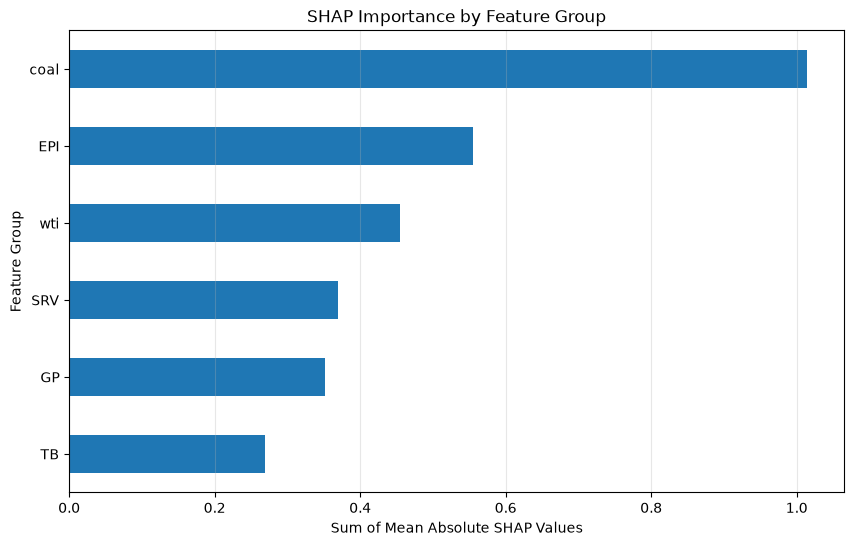

In [179]:
plt.figure(figsize=(10, 6))

group_importance.sort_values().plot(
    kind="barh"
)

plt.title("SHAP Importance by Feature Group")
plt.xlabel("Sum of Mean Absolute SHAP Values")
plt.ylabel("Feature Group")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [180]:
# Lấy danh sách biến không thuộc nhóm coal
features_no_coal = [
    col for col in features_multi
    if not col.startswith("coal_Lag")
]

print("Số biến ban đầu:", len(features_multi))
print("Số biến sau khi bỏ Coal:", len(features_no_coal))

print("\nCác biến còn lại:")
print(features_no_coal)

Số biến ban đầu: 36
Số biến sau khi bỏ Coal: 30

Các biến còn lại:
['wti_Lag1', 'wti_Lag2', 'wti_Lag3', 'wti_Lag5', 'wti_Lag10', 'wti_Lag20', 'GP_Lag1', 'GP_Lag2', 'GP_Lag3', 'GP_Lag5', 'GP_Lag10', 'GP_Lag20', 'TB_Lag1', 'TB_Lag2', 'TB_Lag3', 'TB_Lag5', 'TB_Lag10', 'TB_Lag20', 'EPI_Lag1', 'EPI_Lag2', 'EPI_Lag3', 'EPI_Lag5', 'EPI_Lag10', 'EPI_Lag20', 'SRV_Lag1', 'SRV_Lag2', 'SRV_Lag3', 'SRV_Lag5', 'SRV_Lag10', 'SRV_Lag20']


In [181]:
# Chỉ lấy 30 biến còn lại
X_train_no_coal = X_train_multi[features_no_coal]
X_test_no_coal = X_test_multi[features_no_coal]

print("Train:", X_train_no_coal.shape)
print("Test:", X_test_no_coal.shape)

Train: (3356, 30)
Test: (839, 30)


In [182]:
# Khởi tạo mô hình
model_no_coal = XGBRegressor(**xgb_params)

# Huấn luyện bằng mục tiêu WTI_Change
model_no_coal.fit(
    X_train_no_coal,
    y_train_change_multi
)

print("Đã huấn luyện xong E4!")

Đã huấn luyện xong E4!


In [183]:
# Dự báo mức thay đổi giá
pred_change_no_coal = model_no_coal.predict(
    X_test_no_coal
)

# Lấy giá WTI phiên trước
previous_price = X_test_multi["wti_Lag1"].values

# Khôi phục giá WTI
pred_price_no_coal = (
    previous_price + pred_change_no_coal
)

print("5 mức thay đổi dự báo:")
print(pred_change_no_coal[:5])

print("\n5 giá WTI dự báo:")
print(pred_price_no_coal[:5])

5 mức thay đổi dự báo:
[ 1.4000409   0.57898134  1.559262    1.1699116  -0.05294089]

5 giá WTI dự báo:
[26.49004086 20.05898134 24.88926204 22.19991162 20.69705911]


In [184]:
results_no_coal = evaluate_model(
    y_test_multi,
    pred_price_no_coal,
    X_test_multi["wti_Lag1"]
)

display(
    pd.DataFrame(
        [results_no_coal],
        index=["E4 - Without Coal"]
    ).round(4)
)

,MAE,RMSE,R2,DA (%)
E4 - Without Coal,1.6472,3.2793,0.9805,46.7223


In [185]:
# Chọn 500 quan sát trong tập Test
X_shap_no_coal = X_test_no_coal.sample(
    n=min(500, len(X_test_no_coal)),
    random_state=42
)

# Tạo SHAP Explainer
explainer_no_coal = shap.TreeExplainer(model_no_coal)

# Tính SHAP values
shap_values_no_coal = explainer_no_coal(X_shap_no_coal)

print("SHAP shape:", shap_values_no_coal.values.shape)

SHAP shape: (500, 30)


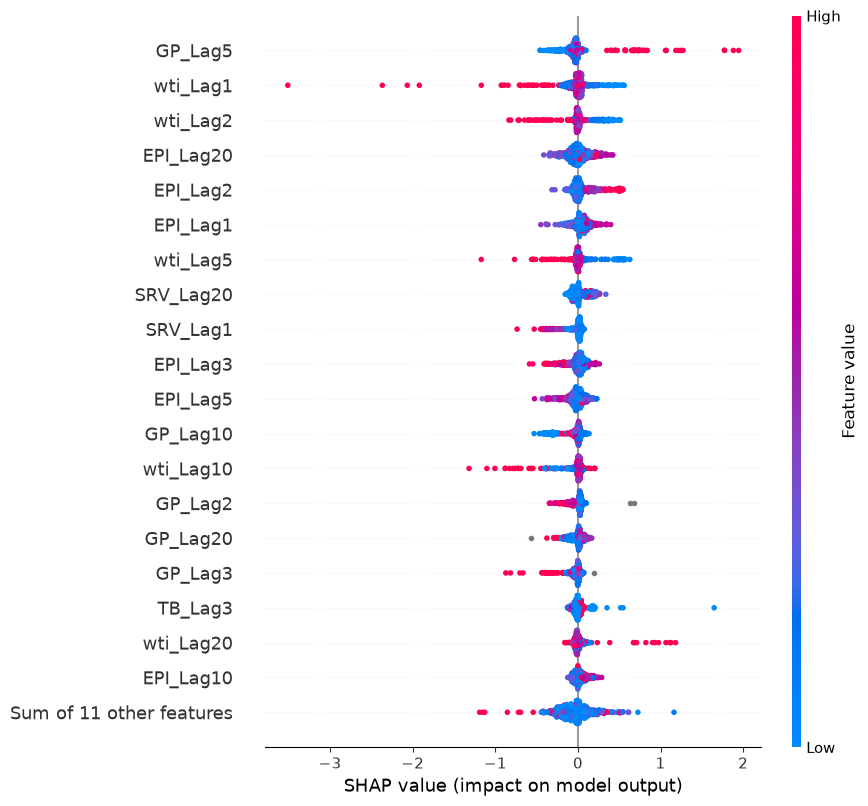

In [186]:
shap.plots.beeswarm(
    shap_values_no_coal,
    max_display=20
)

In [187]:
shap_importance_no_coal = pd.DataFrame({
    "Feature": X_shap_no_coal.columns,
    "Importance": np.abs(
        shap_values_no_coal.values
    ).mean(axis=0)
})

shap_importance_no_coal["Group"] = (
    shap_importance_no_coal["Feature"]
    .apply(lambda x: x.split("_Lag")[0])
)

group_importance_no_coal = (
    shap_importance_no_coal
    .groupby("Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

display(group_importance_no_coal.to_frame())

,Importance
Group,
wti,0.457662
EPI,0.456478
GP,0.410586
SRV,0.307176
TB,0.203801


In [188]:
# Các nhóm biến cần thử loại bỏ
groups_to_remove = ["GP", "EPI", "SRV", "TB"]

for group in groups_to_remove:
    remaining_features = [
        col for col in features_no_coal
        if not col.startswith(group + "_Lag")
    ]

    print(
        f"Bỏ {group}: còn {len(remaining_features)} biến"
    )

Bỏ GP: còn 24 biến
Bỏ EPI: còn 24 biến
Bỏ SRV: còn 24 biến
Bỏ TB: còn 24 biến


In [189]:
# Các nhóm biến cần loại bỏ
groups_to_remove = ["GP", "EPI", "SRV", "TB"]

# Lưu kết quả
ablation_results = []

# Lưu mô hình và dự báo
ablation_models = {}

for group in groups_to_remove:

    print(f"\nĐang thực hiện: Remove {group}")

    # Lấy các biến còn lại
    remaining_features = [
        col for col in features_no_coal
        if not col.startswith(group + "_Lag")
    ]

    # Tạo Train và Test
    X_train_abl = X_train_multi[remaining_features]
    X_test_abl = X_test_multi[remaining_features]

    # Khởi tạo và huấn luyện
    model_abl = XGBRegressor(**xgb_params)

    model_abl.fit(
        X_train_abl,
        y_train_change_multi
    )

    # Dự báo mức thay đổi
    pred_change = model_abl.predict(X_test_abl)

    # Khôi phục giá WTI
    previous_price = X_test_multi["wti_Lag1"].values
    pred_price = previous_price + pred_change

    # Đánh giá
    result = evaluate_model(
        y_test_multi,
        pred_price,
        previous_price
    )

    # Lưu kết quả
    ablation_results.append({
        "Experiment": f"Without {group}",
        "Features": len(remaining_features),
        **result
    })

    ablation_models[group] = {
        "model": model_abl,
        "features": remaining_features,
        "prediction": pred_price
    }

    print("Hoàn thành:", group)

print("\nĐã hoàn thành 4 thí nghiệm!")


Đang thực hiện: Remove GP
Hoàn thành: GP

Đang thực hiện: Remove EPI
Hoàn thành: EPI

Đang thực hiện: Remove SRV
Hoàn thành: SRV

Đang thực hiện: Remove TB
Hoàn thành: TB

Đã hoàn thành 4 thí nghiệm!


In [190]:
# Kết quả E4 đã có
baseline_no_coal = {
    "Experiment": "E4 - Without Coal",
    "Features": len(features_no_coal),
    **results_no_coal
}

# Tổng hợp kết quả
all_ablation_results = pd.DataFrame(
    [baseline_no_coal] + ablation_results
)

display(
    all_ablation_results.round(4)
)

,Experiment,Features,MAE,RMSE,R2,DA (%)
0,E4 - Without Coal,30,1.6472,3.2793,0.9805,46.7223
1,Without GP,24,1.6383,3.2868,0.9804,47.0799
2,Without EPI,24,1.6516,3.3068,0.9802,48.9869
3,Without SRV,24,1.7058,3.2865,0.9804,47.1990
4,Without TB,24,1.6477,3.2862,0.9804,49.1061


In [191]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

print("Số Fold:", tscv.get_n_splits())

Số Fold: 5


In [192]:
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train_multi), start=1
):
    print(f"\nFold {fold}")
    print("Train:", len(train_idx))
    print("Validation:", len(val_idx))

    print(
        "Train dates:",
        data_multi_model["Date"].iloc[train_idx[0]],
        "->",
        data_multi_model["Date"].iloc[train_idx[-1]]
    )

    print(
        "Validation dates:",
        data_multi_model["Date"].iloc[val_idx[0]],
        "->",
        data_multi_model["Date"].iloc[val_idx[-1]]
    )


Fold 1
Train: 561
Validation: 559
Train dates: 2006-11-13 00:00:00 -> 2009-02-05 00:00:00
Validation dates: 2009-02-06 00:00:00 -> 2011-04-26 00:00:00

Fold 2
Train: 1120
Validation: 559
Train dates: 2006-11-13 00:00:00 -> 2011-04-26 00:00:00
Validation dates: 2011-04-27 00:00:00 -> 2013-07-15 00:00:00

Fold 3
Train: 1679
Validation: 559
Train dates: 2006-11-13 00:00:00 -> 2013-07-15 00:00:00
Validation dates: 2013-07-16 00:00:00 -> 2015-10-01 00:00:00

Fold 4
Train: 2238
Validation: 559
Train dates: 2006-11-13 00:00:00 -> 2015-10-01 00:00:00
Validation dates: 2015-10-02 00:00:00 -> 2017-12-20 00:00:00

Fold 5
Train: 2797
Validation: 559
Train dates: 2006-11-13 00:00:00 -> 2017-12-20 00:00:00
Validation dates: 2017-12-21 00:00:00 -> 2020-03-19 00:00:00


In [193]:

# Hai bộ biến cần so sánh
features_e4 = features_no_coal

features_e5 = [
    col for col in features_no_coal
    if not col.startswith("GP_Lag")
]

# Chuẩn bị dữ liệu Train
y_train_change = (
    data_multi_model["WTI_Change"]
    .iloc[:split_multi]
)

# Giá WTI thực tế và giá phiên trước trong tập Train
actual_price_train = y_train_multi

previous_price_train = (
    data_multi_model["wti_Lag1"]
    .iloc[:split_multi]
)

# Kiểm tra số dòng có khớp không
assert len(X_train_multi) == len(y_train_change)
assert len(X_train_multi) == len(actual_price_train)
assert len(X_train_multi) == len(previous_price_train)

# Lưu kết quả từng Fold
cv_results = []

# TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train_multi), start=1
):

    print(f"\nĐang chạy Fold {fold}...")

    # Chia dữ liệu theo Fold
    y_train_fold = y_train_change.iloc[train_idx]

    # Giá WTI thực tế và giá phiên trước
    actual_price = actual_price_train.iloc[val_idx].values

    previous_price = (
        previous_price_train.iloc[val_idx].values
    )

    # Hai mô hình
    models = {
        "E4 - Without Coal": features_e4,
        "E5 - Without Coal and GP": features_e5
    }

    for model_name, selected_features in models.items():

        # Lấy dữ liệu đầu vào theo Fold
        X_train_fold = (
            X_train_multi.iloc[train_idx][selected_features]
        )

        X_val_fold = (
            X_train_multi.iloc[val_idx][selected_features]
        )

        # Huấn luyện
        model = XGBRegressor(**xgb_params)

        model.fit(
            X_train_fold,
            y_train_fold
        )

        # Dự báo mức thay đổi
        pred_change = model.predict(X_val_fold)

        # Khôi phục giá WTI
        pred_price = previous_price + pred_change

        # Đánh giá
        metrics = evaluate_model(
            actual_price,
            pred_price,
            previous_price
        )

        cv_results.append({
            "Fold": fold,
            "Model": model_name,
            "Features": len(selected_features),
            **metrics
        })

    print(f"Hoàn thành Fold {fold}!")

print("\nĐã hoàn thành Cross Validation!")



Đang chạy Fold 1...
Hoàn thành Fold 1!

Đang chạy Fold 2...
Hoàn thành Fold 2!

Đang chạy Fold 3...
Hoàn thành Fold 3!

Đang chạy Fold 4...
Hoàn thành Fold 4!

Đang chạy Fold 5...
Hoàn thành Fold 5!

Đã hoàn thành Cross Validation!


In [194]:
print(cv_results_df.columns.tolist())

['Fold', 'Model', 'Features', 'MAE', 'RMSE', 'R2', 'DA (%)']


In [195]:
display(cv_results_df.head())

,Fold,Model,Features,MAE,RMSE,R2,DA (%)
0,1,E4 - Without Coal,30,1.681622,2.134479,0.978449,48.300537
1,1,E5 - Without Coal and GP,24,1.583993,1.989714,0.981273,48.837209
2,2,E4 - Without Coal,30,1.478278,1.992883,0.914024,50.089445
3,2,E5 - Without Coal and GP,24,1.511520,2.045610,0.909414,48.837209
4,3,E4 - Without Coal,30,1.247792,1.619396,0.995332,46.869410


In [196]:
cv_results_df = pd.DataFrame(cv_results)

cv_summary = cv_results_df.groupby("Model")[
    ["MAE", "RMSE", "R2", "DA (%)"]
].mean()

display(cv_summary)

,MAE,RMSE,R2,DA (%)
Model,,,,
E4 - Without Coal,1.267613,1.690145,0.963350,49.087657
E5 - Without Coal and GP,1.242854,1.666712,0.961627,49.731664


In [197]:

# Tổng hợp kết quả Cross Validation
cv_summary = cv_results_df.groupby("Model").agg({
    "MAE": ["mean", "std"],
    "RMSE": ["mean", "std"],
    "R2": ["mean", "std"],
    "DA (%)": ["mean", "std"]
})

# Làm tròn 4 chữ số
cv_summary = cv_summary.round(4)

display(cv_summary)


MAE            RMSE              R2          \
                            mean     std    mean     std    mean     std   
Model                                                                      
E4 - Without Coal         1.2676  0.3161  1.6901  0.3631  0.9634  0.0305   
E5 - Without Coal and GP  1.2429  0.2845  1.6667  0.3217  0.9616  0.0331   

                           DA (%)          
                             mean     std  
Model                                      
E4 - Without Coal         49.0877  1.4676  
E5 - Without Coal and GP  49.7317  1.3972

In [198]:

# Huấn luyện và đánh giá E4, E5 trên tập Test

test_results = []

models_features = {
    "E4 - Without Coal": features_e4,
    "E5 - Without Coal and GP": features_e5
}

# Giá WTI thực tế và giá phiên trước trên tập Test
actual_price_test = y_test_multi.values

previous_price_test = (
    data_multi_model["wti_Lag1"]
    .iloc[split_multi:]
    .values
)

for model_name, selected_features in models_features.items():

    # Lấy Features
    X_train_selected = X_train_multi[selected_features]
    X_test_selected = X_test_multi[selected_features]

    # Tạo và huấn luyện mô hình
    model = XGBRegressor(**xgb_params)

    model.fit(
        X_train_selected,
        y_train_change_multi
    )

    # Dự báo mức thay đổi
    pred_change = model.predict(X_test_selected)

    # Khôi phục giá WTI
    pred_price = previous_price_test + pred_change

    # Đánh giá
    metrics = evaluate_model(
        actual_price_test,
        pred_price,
        previous_price_test
    )

    test_results.append({
        "Model": model_name,
        **metrics
    })

# Hiển thị kết quả
test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))


,Model,MAE,RMSE,R2,DA (%)
0,E4 - Without Coal,1.6472,3.2793,0.9805,46.7223
1,E5 - Without Coal and GP,1.6383,3.2868,0.9804,47.0799


In [199]:
cv_summary = (
    cv_results_df
    .groupby("Model")
    .agg({
        "MAE": ["mean", "std"],
        "RMSE": ["mean", "std"],
        "R2": ["mean", "std"],
        "DA (%)": ["mean", "std"]
    })
)

display(cv_summary.round(4))

MAE            RMSE              R2          \
                            mean     std    mean     std    mean     std   
Model                                                                      
E4 - Without Coal         1.2676  0.3161  1.6901  0.3631  0.9634  0.0305   
E5 - Without Coal and GP  1.2429  0.2845  1.6667  0.3217  0.9616  0.0331   

                           DA (%)          
                             mean     std  
Model                                      
E4 - Without Coal         49.0877  1.4676  
E5 - Without Coal and GP  49.7317  1.3972

In [200]:
param_grid = {
    "n_estimators": [300, 500, 700],
    "learning_rate": [0.01, 0.03, 0.05],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

In [201]:
from sklearn.model_selection import RandomizedSearchCV

xgb_tuning = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=xgb_tuning,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(
    X_train_multi[features_e5],
    y_train_change_multi
)

print("Best parameters:")
print(random_search.best_params_)

print("Best CV MAE:", -random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'subsample': 0.8, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
Best CV MAE: 1.1216237782871272


In [202]:
best_params = random_search.best_params_

best_model_e5 = XGBRegressor(
    **best_params,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

best_model_e5.fit(
    X_train_multi[features_e5],
    y_train_change_multi
)

print("Đã huấn luyện xong mô hình E5 tối ưu!")

Đã huấn luyện xong mô hình E5 tối ưu!


In [203]:
# Dự đoán mức thay đổi giá WTI
y_pred_change = best_model_e5.predict(
    X_test_multi[features_e5]
)

# Khôi phục giá WTI dự đoán
previous_price = data_multi_model["wti_Lag1"].iloc[len(X_train_multi):].values

y_pred_price = previous_price + y_pred_change

# Đánh giá mô hình
results_best_e5 = evaluate_model(
    y_test_change_multi + previous_price,
    y_pred_price,
    previous_price
)

print("Kết quả E5 sau tối ưu:")
print(results_best_e5)

Kết quả E5 sau tối ưu:
{'MAE': 1.5724508069046974, 'RMSE': np.float64(3.2370185337567783), 'R2': 0.9809907346477114, 'DA (%)': np.float64(49.9404052443385)}


In [204]:
import shap

explainer_e5 = shap.TreeExplainer(best_model_e5)

X_test_sample = X_test_multi[features_e5].sample(
    n=500,
    random_state=42
)

shap_values_e5 = explainer_e5.shap_values(X_test_sample)

print("SHAP shape:", shap_values_e5.shape)

SHAP shape: (500, 24)


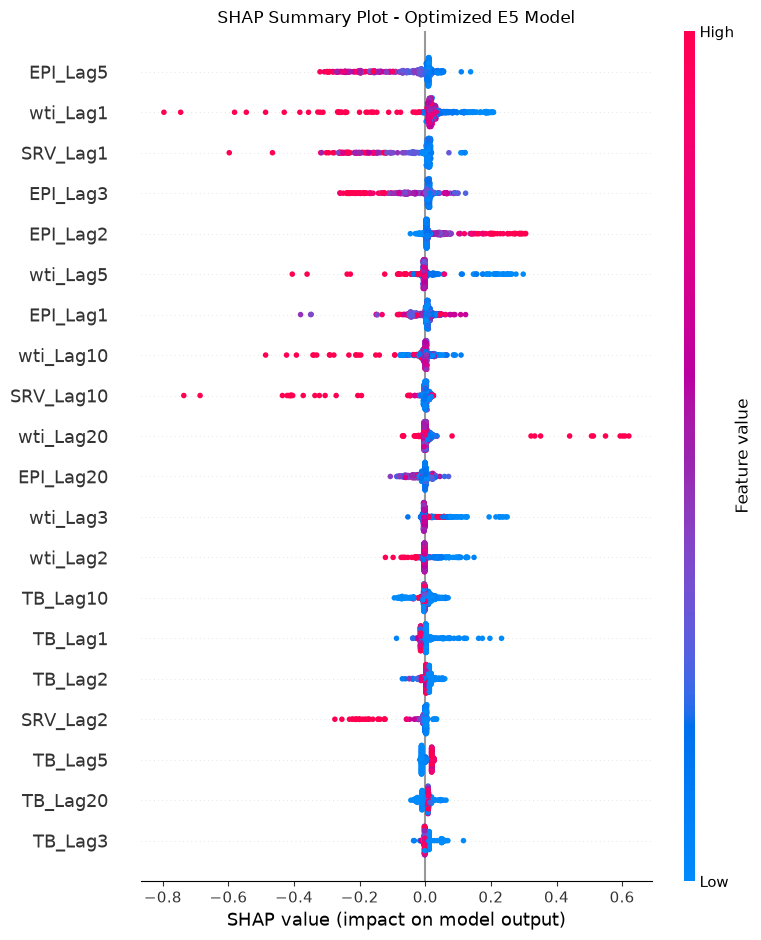

In [205]:
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values_e5,
    X_test_sample,
    show=False
)

plt.title("SHAP Summary Plot - Optimized E5 Model")
plt.tight_layout()
plt.show()

In [206]:
import pandas as pd
import numpy as np

# Tính giá trị SHAP tuyệt đối trung bình của từng đặc trưng
shap_importance = np.abs(shap_values_e5).mean(axis=0)

# Tạo bảng gồm tên đặc trưng và mức độ quan trọng
shap_df = pd.DataFrame({
    "Feature": X_test_sample.columns,
    "Importance": shap_importance
})

# Xác định nhóm biến từ tên đặc trưng
shap_df["Group"] = shap_df["Feature"].str.split("_Lag").str[0]

# Cộng mức độ quan trọng của các Lag thuộc cùng nhóm
group_importance = (
    shap_df.groupby("Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

print("Group SHAP Importance:")
print(group_importance)

Group SHAP Importance:
Group
EPI    0.180443
wti    0.149574
SRV    0.099577
TB     0.077432
Name: Importance, dtype: float32


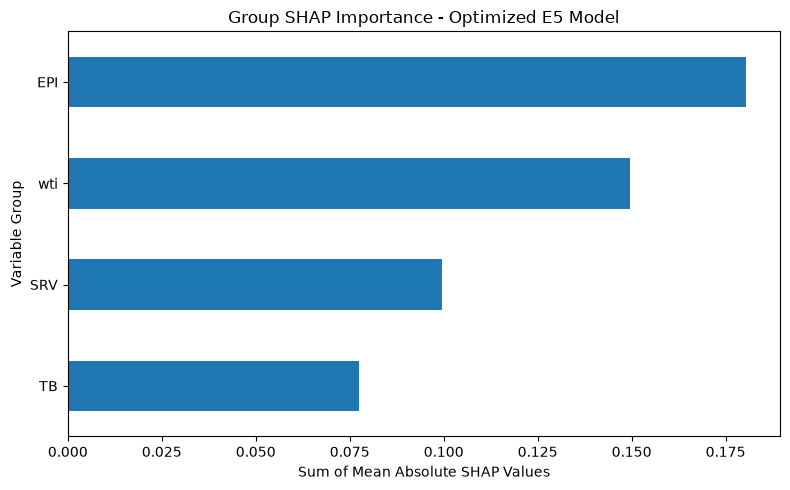

In [207]:
plt.figure(figsize=(8, 5))

group_importance.sort_values().plot(
    kind="barh"
)

plt.title("Group SHAP Importance - Optimized E5 Model")
plt.xlabel("Sum of Mean Absolute SHAP Values")
plt.ylabel("Variable Group")
plt.tight_layout()
plt.show()

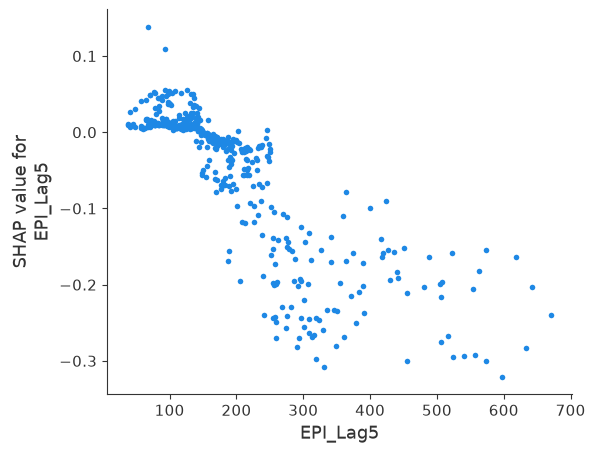

In [208]:
shap.dependence_plot(
    "EPI_Lag5",
    shap_values_e5,
    X_test_sample,
    interaction_index=None
)

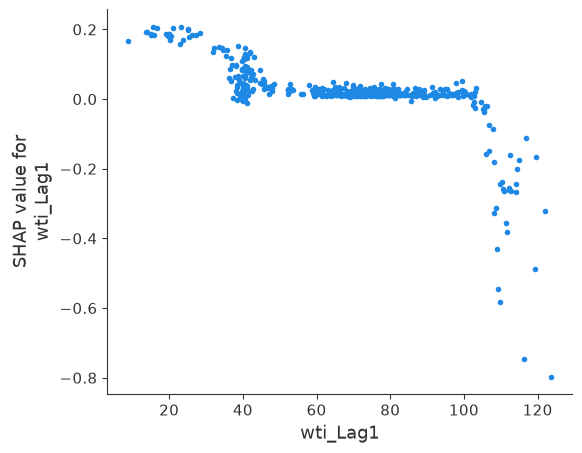

In [209]:
shap.dependence_plot(
    "wti_Lag1",
    shap_values_e5,
    X_test_sample,
    interaction_index=None
)

In [210]:
# Tính SHAP Interaction Values
interaction_values = explainer_e5.shap_interaction_values(
    X_test_sample
)

print("Interaction shape:", interaction_values.shape)

Interaction shape: (500, 24, 24)


In [211]:
# Tính mức độ tương tác trung bình tuyệt đối
mean_interaction = np.abs(interaction_values).mean(axis=0)

# Chỉ lấy nửa trên của ma trận, không lấy đường chéo
upper_indices = np.triu_indices_from(
    mean_interaction, k=1
)

interaction_df = pd.DataFrame({
    "Feature 1": X_test_sample.columns[upper_indices[0]],
    "Feature 2": X_test_sample.columns[upper_indices[1]],
    "Interaction Importance": mean_interaction[upper_indices]
})

# Sắp xếp giảm dần
interaction_df = interaction_df.sort_values(
    by="Interaction Importance",
    ascending=False
)

print("Top 10 feature interactions:")
print(interaction_df.head(10).to_string(index=False))

Top 10 feature interactions:
Feature 1 Feature 2  Interaction Importance
 wti_Lag1  EPI_Lag1                0.012666
 wti_Lag1  wti_Lag2                0.011582
 EPI_Lag3  EPI_Lag5                0.011282
 wti_Lag1  wti_Lag5                0.009229
 EPI_Lag1  EPI_Lag3                0.008540
 SRV_Lag1 SRV_Lag10                0.008448
 wti_Lag1  EPI_Lag3                0.007652
  TB_Lag2   TB_Lag5                0.007281
wti_Lag10  EPI_Lag5                0.006801
 wti_Lag1  EPI_Lag5                0.006539


In [212]:
pair = interaction_df[
    (
        (interaction_df["Feature 1"] == "EPI_Lag5") &
        (interaction_df["Feature 2"] == "wti_Lag1")
    ) |
    (
        (interaction_df["Feature 1"] == "wti_Lag1") &
        (interaction_df["Feature 2"] == "EPI_Lag5")
    )
]

print(pair)

   Feature 1 Feature 2  Interaction Importance
14  wti_Lag1  EPI_Lag5                0.006539


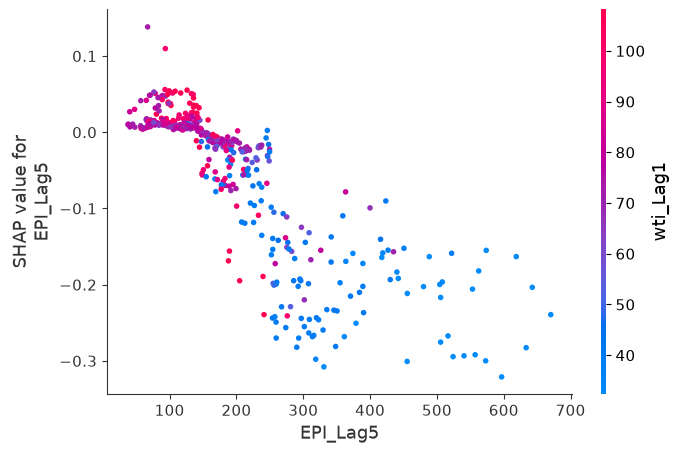

In [213]:
shap.dependence_plot(
    "EPI_Lag5",
    shap_values_e5,
    X_test_sample,
    interaction_index="wti_Lag1"
)

In [214]:
# Lấy vị trí của hai đặc trưng
idx_epi = X_test_sample.columns.get_loc("EPI_Lag5")
idx_wti = X_test_sample.columns.get_loc("wti_Lag1")

# Lấy SHAP interaction của cặp biến
pair_interaction = interaction_values[:, idx_epi, idx_wti]

print("Mean interaction:", np.mean(pair_interaction))
print("Mean absolute interaction:", np.mean(np.abs(pair_interaction)))
print("Min interaction:", np.min(pair_interaction))
print("Max interaction:", np.max(pair_interaction))

Mean interaction: 0.0038525232
Mean absolute interaction: 0.0065393974
Min interaction: -0.13997924
Max interaction: 0.023644602


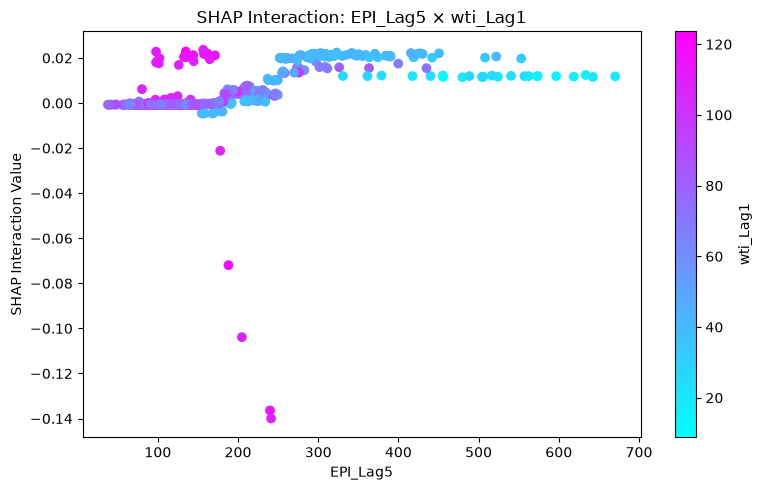

In [215]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test_sample["EPI_Lag5"],
    pair_interaction,
    c=X_test_sample["wti_Lag1"],
    cmap="cool"
)

plt.colorbar(label="wti_Lag1")
plt.xlabel("EPI_Lag5")
plt.ylabel("SHAP Interaction Value")
plt.title("SHAP Interaction: EPI_Lag5 × wti_Lag1")
plt.tight_layout()
plt.show()

In [216]:
# Tạo bảng dữ liệu tương tác của cặp EPI_Lag5 và wti_Lag1
interaction_check = pd.DataFrame({
    "EPI_Lag5": X_test_sample["EPI_Lag5"].values,
    "wti_Lag1": X_test_sample["wti_Lag1"].values,
    "Interaction": pair_interaction
})

# Sắp xếp các quan sát có tương tác âm mạnh nhất
extreme_interactions = interaction_check.sort_values(
    by="Interaction",
    ascending=True
)

print("10 observations with strongest negative interactions:")
print(extreme_interactions.head(10).to_string(index=False))

10 observations with strongest negative interactions:
 EPI_Lag5  wti_Lag1  Interaction
   241.25    108.24    -0.139979
   239.83    116.20    -0.136394
   204.82    108.81    -0.103884
   188.05    119.26    -0.071901
   177.73    106.78    -0.021161
   158.05     39.34    -0.004610
   156.70     45.64    -0.004593
   154.81     44.71    -0.004588
   167.77     37.27    -0.004588
   169.10     39.69    -0.004581


In [217]:
seeds = [42, 100, 2026]

stability_results = []

idx_epi = X_test_sample.columns.get_loc("EPI_Lag5")
idx_wti = X_test_sample.columns.get_loc("wti_Lag1")

for seed in seeds:

    sample = X_test_multi[features_e5].sample(
        n=500,
        random_state=seed
    )

    interactions = explainer_e5.shap_interaction_values(sample)

    pair_values = interactions[:, idx_epi, idx_wti]

    stability_results.append({
        "Random State": seed,
        "Mean Interaction": np.mean(pair_values),
        "Mean Absolute Interaction": np.mean(np.abs(pair_values)),
        "Minimum": np.min(pair_values),
        "Maximum": np.max(pair_values),
        "Negative Percentage": np.mean(pair_values < 0) * 100
    })

stability_df = pd.DataFrame(stability_results)

print(stability_df.round(6).to_string(index=False))

 Random State  Mean Interaction  Mean Absolute Interaction   Minimum  Maximum  Negative Percentage
           42          0.003853                   0.006539 -0.139979 0.023645                 54.4
          100          0.004613                   0.005766 -0.071901 0.023645                 56.4
         2026          0.003670                   0.006073 -0.144533 0.023645                 56.6


In [218]:
# Tính SHAP Interaction trên toàn bộ Test set
interaction_all = explainer_e5.shap_interaction_values(
    X_test_multi[features_e5]
)

# Vị trí hai đặc trưng
idx_epi = X_test_sample.columns.get_loc("EPI_Lag5")
idx_wti = X_test_sample.columns.get_loc("wti_Lag1")

# Trích xuất tương tác
pair_all = interaction_all[:, idx_epi, idx_wti]

# Tổng hợp kết quả
print("Number of observations:", len(pair_all))
print("Mean Interaction:", np.mean(pair_all))
print("Mean Absolute Interaction:", np.mean(np.abs(pair_all)))
print("Minimum:", np.min(pair_all))
print("Maximum:", np.max(pair_all))
print("Negative Percentage:", np.mean(pair_all < 0) * 100)

Number of observations: 839
Mean Interaction: 0.0036661986
Mean Absolute Interaction: 0.0061201234
Minimum: -0.14453338
Maximum: 0.023644602
Negative Percentage: 57.33015494636472


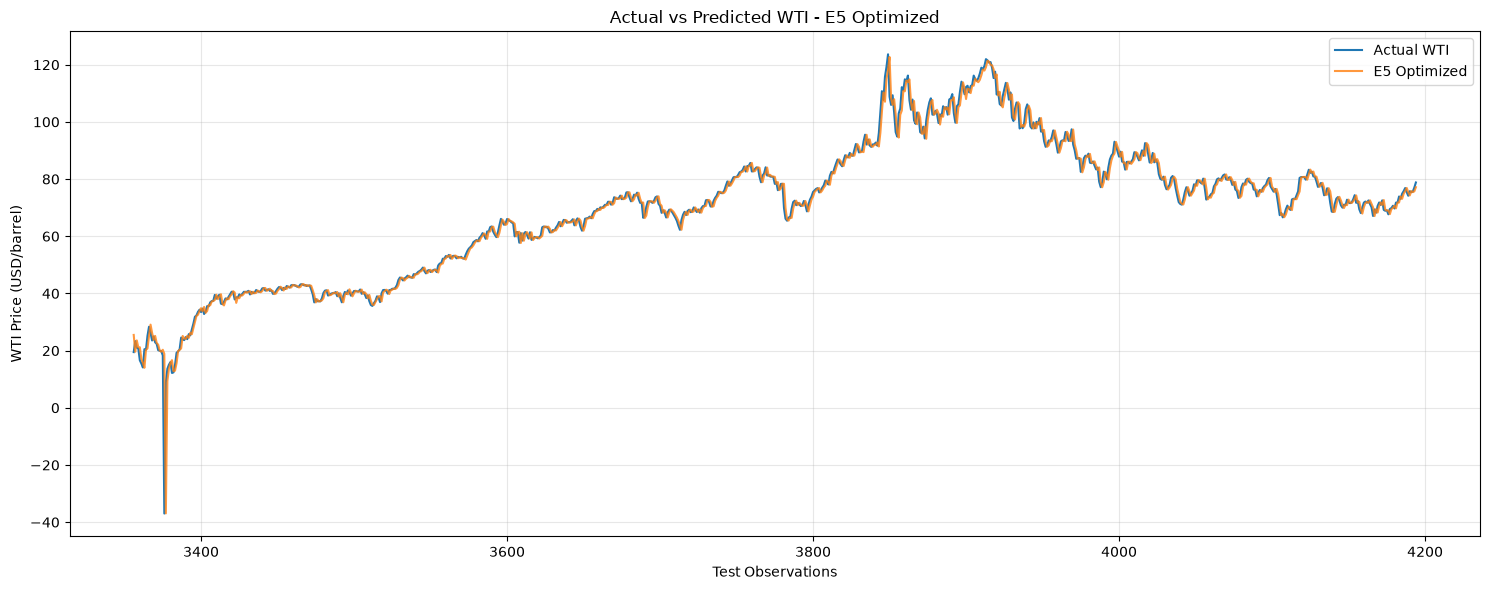

In [219]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test_change_multi.index,
    y_test_change_multi.values + previous_price,
    label="Actual WTI",
    linewidth=1.5
)

plt.plot(
    y_test_change_multi.index,
    y_pred_price,
    label="E5 Optimized",
    alpha=0.8
)

plt.title("Actual vs Predicted WTI - E5 Optimized")
plt.xlabel("Test Observations")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

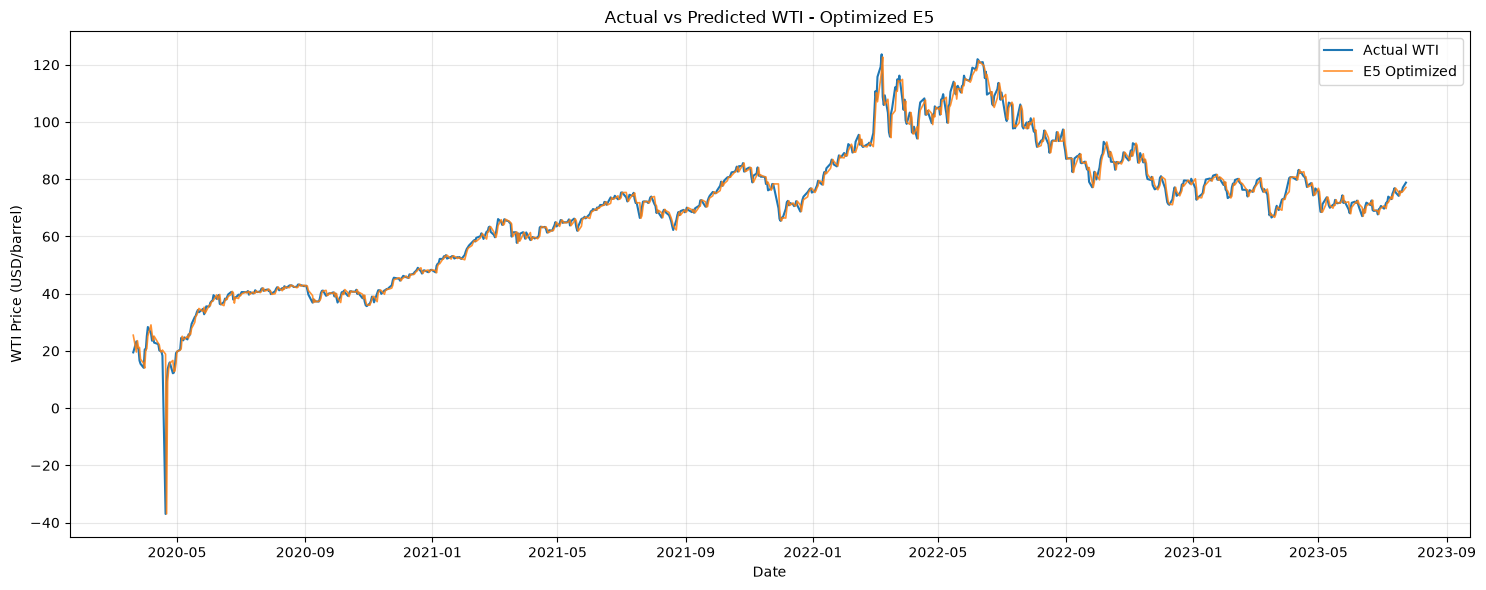

In [220]:
# Lấy ngày tháng của tập Test
test_dates = data_multi_model["Date"].iloc[len(X_train_multi):]

# Lấy giá WTI thực tế
actual_wti = data_multi_model["wti"].iloc[len(X_train_multi):]

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    actual_wti,
    label="Actual WTI",
    linewidth=1.5
)

plt.plot(
    test_dates,
    y_pred_price,
    label="E5 Optimized",
    linewidth=1.2,
    alpha=0.85
)

plt.title("Actual vs Predicted WTI - Optimized E5")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [221]:
# Kiểm tra các biến liên quan đến mô hình và dữ liệu dự đoán
for name in sorted(globals()):
    if any(key in name.lower() for key in [
        "model_change",
        "x_test_uni",
        "y_pred",
        "features_uni"
    ]):
        print(name)

X_test_uni
features_uni
model_change_multi
model_change_uni
y_pred_change
y_pred_change_uni
y_pred_multi
y_pred_price
y_pred_price_uni
y_pred_uni


In [222]:
# Dự đoán mức thay đổi giá WTI bằng E3 Univariate
y_pred_change_uni = model_change_uni.predict(
    X_test_uni[features_uni]
)

# Lấy giá WTI phiên trước
previous_price_uni = data_uni_model["WTI_Lag1"].iloc[
    -len(X_test_uni):
].values

# Khôi phục giá WTI dự đoán
y_pred_price_uni = previous_price_uni + y_pred_change_uni

print("E3 prediction shape:", y_pred_price_uni.shape)
print("E5 prediction shape:", y_pred_price.shape)

E3 prediction shape: (839,)
E5 prediction shape: (839,)


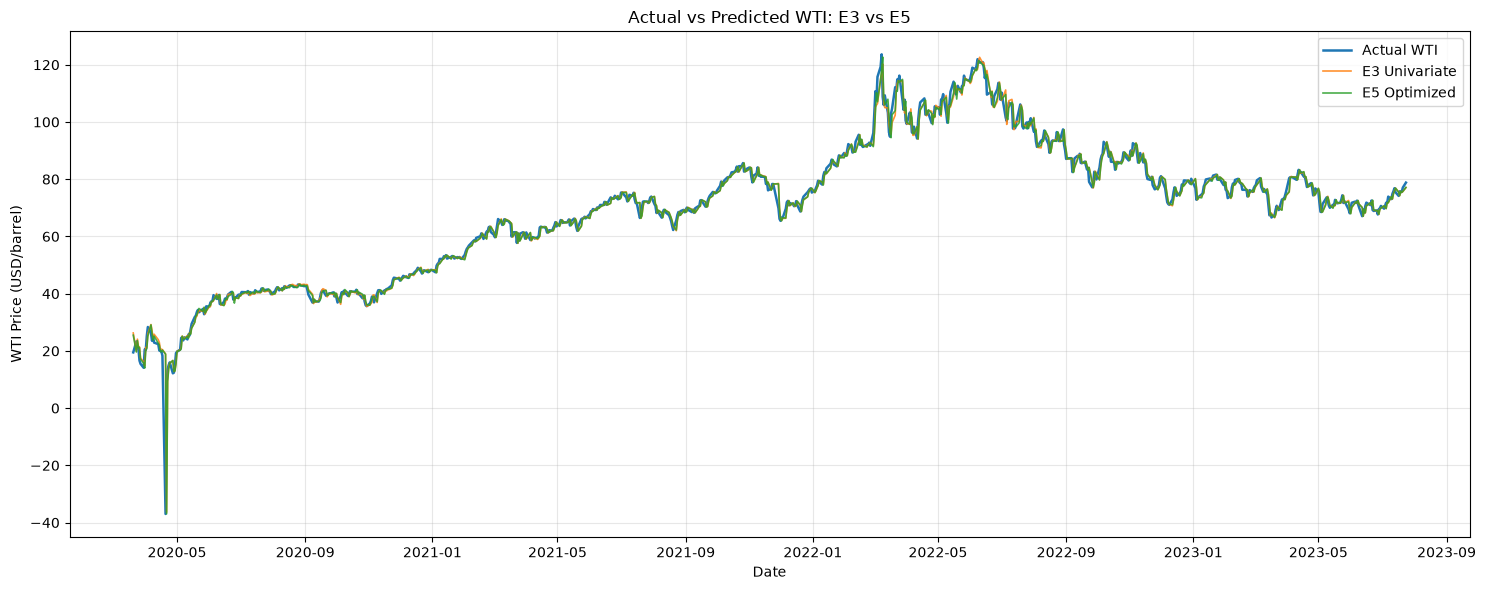

In [223]:
import matplotlib.pyplot as plt

# Ngày tháng và giá WTI thực tế
test_dates = data_uni_model["Date"].iloc[-len(X_test_uni):]
actual_wti = data_uni_model["wti"].iloc[-len(X_test_uni):]

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    actual_wti.values,
    label="Actual WTI",
    linewidth=1.8
)

plt.plot(
    test_dates,
    y_pred_price_uni,
    label="E3 Univariate",
    linewidth=1.2,
    alpha=0.85
)

plt.plot(
    test_dates,
    y_pred_price,
    label="E5 Optimized",
    linewidth=1.2,
    alpha=0.85
)

plt.title("Actual vs Predicted WTI: E3 vs E5")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [224]:
# Đánh giá E3 Univariate
results_e3 = evaluate_model(
    actual_wti.values,
    y_pred_price_uni,
    previous_price_uni
)

# Đánh giá E5 Optimized
results_e5 = evaluate_model(
    actual_wti.values,
    y_pred_price,
    previous_price_uni
)

comparison = pd.DataFrame({
    "E3 Univariate": results_e3,
    "E5 Optimized": results_e5
})

print(comparison.round(4))

        E3 Univariate  E5 Optimized
MAE            1.5856        1.5725
RMSE           3.2267        3.2370
R2             0.9811        0.9810
DA (%)        48.8677       49.9404


In [225]:
# Tạo bảng sai số của hai mô hình
error_comparison = pd.DataFrame({
    "Date": test_dates.values,
    "Actual": actual_wti.values,
    "E3_Predicted": y_pred_price_uni,
    "E5_Predicted": y_pred_price
})

# Tính sai số
error_comparison["E3_Error"] = (
    error_comparison["Actual"] -
    error_comparison["E3_Predicted"]
)

error_comparison["E5_Error"] = (
    error_comparison["Actual"] -
    error_comparison["E5_Predicted"]
)

# Sai số tuyệt đối
error_comparison["E3_Abs_Error"] = abs(
    error_comparison["E3_Error"]
)

error_comparison["E5_Abs_Error"] = abs(
    error_comparison["E5_Error"]
)

print(error_comparison.head())

        Date  Actual  E3_Predicted  E5_Predicted  E3_Error  E5_Error  \
0 2020-03-20   19.48     26.269162     25.489885 -6.789162 -6.009885   
1 2020-03-23   23.33     19.870182     19.608308  3.459818  3.721692   
2 2020-03-24   21.03     24.111445     23.577519 -3.081445 -2.547519   
3 2020-03-25   20.75     21.573004     21.118351 -0.823004 -0.368351   
4 2020-03-26   16.60     21.382472     21.183691 -4.782472 -4.583691   

   E3_Abs_Error  E5_Abs_Error  
0      6.789162      6.009885  
1      3.459818      3.721692  
2      3.081445      2.547519  
3      0.823004      0.368351  
4      4.782472      4.583691  


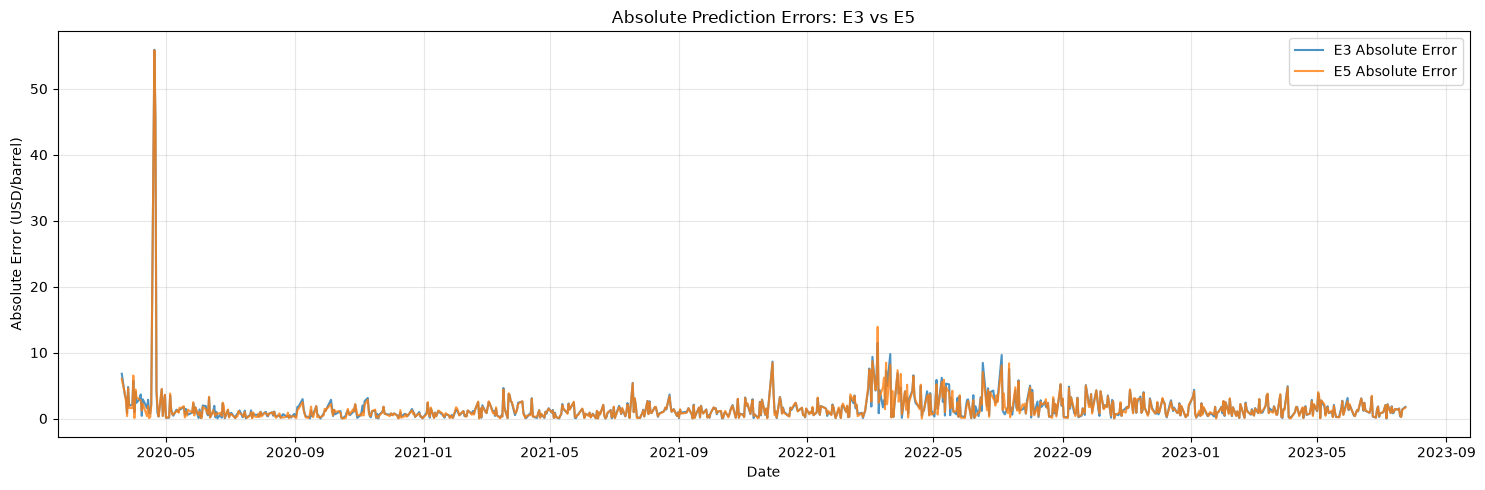

In [226]:
plt.figure(figsize=(15, 5))

plt.plot(
    error_comparison["Date"],
    error_comparison["E3_Abs_Error"],
    label="E3 Absolute Error",
    alpha=0.8
)

plt.plot(
    error_comparison["Date"],
    error_comparison["E5_Abs_Error"],
    label="E5 Absolute Error",
    alpha=0.8
)

plt.title("Absolute Prediction Errors: E3 vs E5")
plt.xlabel("Date")
plt.ylabel("Absolute Error (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [227]:
# So sánh sai số tuyệt đối tại từng quan sát
e3_better = (
    error_comparison["E3_Abs_Error"] <
    error_comparison["E5_Abs_Error"]
).sum()

e5_better = (
    error_comparison["E5_Abs_Error"] <
    error_comparison["E3_Abs_Error"]
).sum()

equal = (
    error_comparison["E3_Abs_Error"] ==
    error_comparison["E5_Abs_Error"]
).sum()

print("E3 has lower error:", e3_better)
print("E5 has lower error:", e5_better)
print("Equal error:", equal)

print("\nPercentage:")
print("E3:", e3_better / len(error_comparison) * 100)
print("E5:", e5_better / len(error_comparison) * 100)

E3 has lower error: 387
E5 has lower error: 452
Equal error: 0

Percentage:
E3: 46.12634088200238
E5: 53.87365911799762


In [228]:
# Sai số lớn nhất của E3
print("Top 10 E3 errors:")
print(
    error_comparison.nlargest(
        10, "E3_Abs_Error"
    )[
        ["Date", "Actual", "E3_Predicted", "E3_Abs_Error"]
    ].to_string(index=False)
)

# Sai số lớn nhất của E5
print("\nTop 10 E5 errors:")
print(
    error_comparison.nlargest(
        10, "E5_Abs_Error"
    )[
        ["Date", "Actual", "E5_Predicted", "E5_Abs_Error"]
    ].to_string(index=False)
)

Top 10 E3 errors:
      Date  Actual  E3_Predicted  E3_Abs_Error
2020-04-20  -36.98     18.938732     55.918732
2020-04-21    8.91    -36.351268     45.261268
2022-03-09  108.81    120.299539     11.489539
2022-03-21  112.14    102.364658      9.775342
2022-07-05  101.55    111.180319      9.630319
2022-03-04  115.77    106.419386      9.350614
2021-11-29   69.88     78.518342      8.638342
2022-06-17  109.56    118.005244      8.445244
2022-03-01  103.66     96.075953      7.584047
2022-07-12   97.69    105.205399      7.515399

Top 10 E5 errors:
      Date  Actual  E5_Predicted  E5_Abs_Error
2020-04-20  -36.98     18.866246     55.846246
2020-04-21    8.91    -36.933392     45.843392
2022-03-09  108.81    122.704656     13.894656
2022-03-04  115.77    107.056803      8.713197
2021-11-29   69.88     78.348128      8.468128
2022-03-17  102.97     94.510826      8.459174
2022-07-12   97.69    106.062700      8.372700
2022-03-21  112.14    103.958928      8.181072
2022-07-05  101.55    1

In [229]:
# Tạo tập dữ liệu loại riêng hai ngày cực đoan
# Chỉ dùng cho phân tích độ nhạy, không thay thế kết quả chính

normal_period = error_comparison[
    ~error_comparison["Date"].isin(
        pd.to_datetime(["2020-04-20", "2020-04-21"])
    )
]

print("Original observations:", len(error_comparison))
print("After excluding two extreme dates:", len(normal_period))

print("\nMAE comparison excluding extreme dates:")

print("E3 MAE:",
      normal_period["E3_Abs_Error"].mean())

print("E5 MAE:",
      normal_period["E5_Abs_Error"].mean())

print("\nRMSE comparison excluding extreme dates:")

print("E3 RMSE:",
      np.sqrt(np.mean(normal_period["E3_Error"] ** 2)))

print("E5 RMSE:",
      np.sqrt(np.mean(normal_period["E5_Error"] ** 2)))

Original observations: 839
After excluding two extreme dates: 837

MAE comparison excluding extreme dates:
E3 MAE: 1.4684550596628643
E5 MAE: 1.4547151607678983

RMSE comparison excluding extreme dates:
E3 RMSE: 2.0623271568937778
E5 RMSE: 2.0654941582580064


In [230]:
from scipy.stats import t

# Sai số dự báo của hai mô hình
e3_error = error_comparison["E3_Error"].values
e5_error = error_comparison["E5_Error"].values

# Chênh lệch bình phương sai số
loss_diff = e3_error**2 - e5_error**2

n = len(loss_diff)

# DM statistic với giả định đơn giản: không có tự tương quan
dm_stat = loss_diff.mean() / (
    loss_diff.std(ddof=1) / np.sqrt(n)
)

# P-value hai phía
p_value = 2 * t.sf(abs(dm_stat), df=n-1)

print("DM statistic:", dm_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("The difference is statistically significant.")
else:
    print("No statistically significant difference.")

DM statistic: -0.45720847900062866
P-value: 0.6476397052586378
No statistically significant difference.


In [231]:
import statsmodels.api as sm
import numpy as np

# Chênh lệch bình phương sai số: E3 - E5
loss_diff = (
    error_comparison["E3_Error"].values**2
    - error_comparison["E5_Error"].values**2
)

X_constant = np.ones((len(loss_diff), 1))

for lag in [1, 5, 10, 20]:
    model_hac = sm.OLS(
        loss_diff,
        X_constant
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": lag}
    )

    print(
        f"Lag {lag}: "
        f"Statistic = {model_hac.tvalues[0]:.4f}, "
        f"P-value = {model_hac.pvalues[0]:.4f}"
    )

Lag 1: Statistic = -0.4714, P-value = 0.6374
Lag 5: Statistic = -0.5123, P-value = 0.6084
Lag 10: Statistic = -0.5091, P-value = 0.6107
Lag 20: Statistic = -0.4795, P-value = 0.6316


In [232]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [233]:
import statsmodels.api as sm

print("statsmodels version:", sm.__version__)

statsmodels version: 0.15.0


In [234]:
import statsmodels.api as sm
import numpy as np

# Chênh lệch bình phương sai số: E3 - E5
loss_diff = (
    error_comparison["E3_Error"].values**2
    - error_comparison["E5_Error"].values**2
)

X_constant = np.ones((len(loss_diff), 1))

for lag in [1, 5, 10, 20]:
    model_hac = sm.OLS(
        loss_diff,
        X_constant
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": lag}
    )

    print(
        f"Lag {lag}: "
        f"Statistic = {model_hac.tvalues[0]:.4f}, "
        f"P-value = {model_hac.pvalues[0]:.4f}"
    )

Lag 1: Statistic = -0.4714, P-value = 0.6374
Lag 5: Statistic = -0.5123, P-value = 0.6084
Lag 10: Statistic = -0.5091, P-value = 0.6107
Lag 20: Statistic = -0.4795, P-value = 0.6316


In [235]:
# Thống kê mô tả giá dầu WTI
wti_stats = data_multi_model["wti"].describe()

print("WTI Descriptive Statistics:")
print(wti_stats)

print("\nSkewness:", data_multi_model["wti"].skew())
print("Kurtosis:", data_multi_model["wti"].kurtosis())

WTI Descriptive Statistics:
count    4195.000000
mean       72.551187
std        23.033020
min       -36.980000
25%        53.210000
50%        71.410000
75%        91.895000
max       145.310000
Name: wti, dtype: float64

Skewness: 0.16571009160832495
Kurtosis: -0.5098137145108255


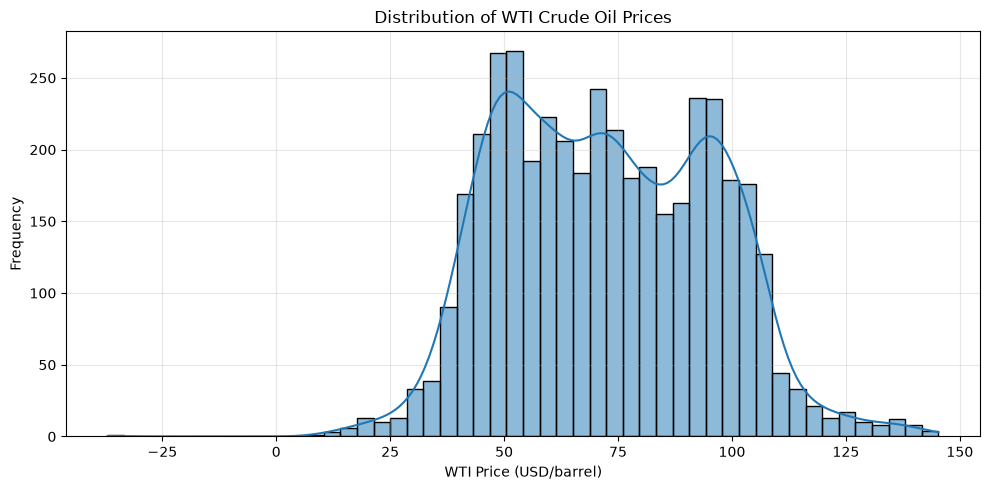

In [236]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data_multi_model["wti"],
    bins=50,
    kde=True
)

plt.title("Distribution of WTI Crude Oil Prices")
plt.xlabel("WTI Price (USD/barrel)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

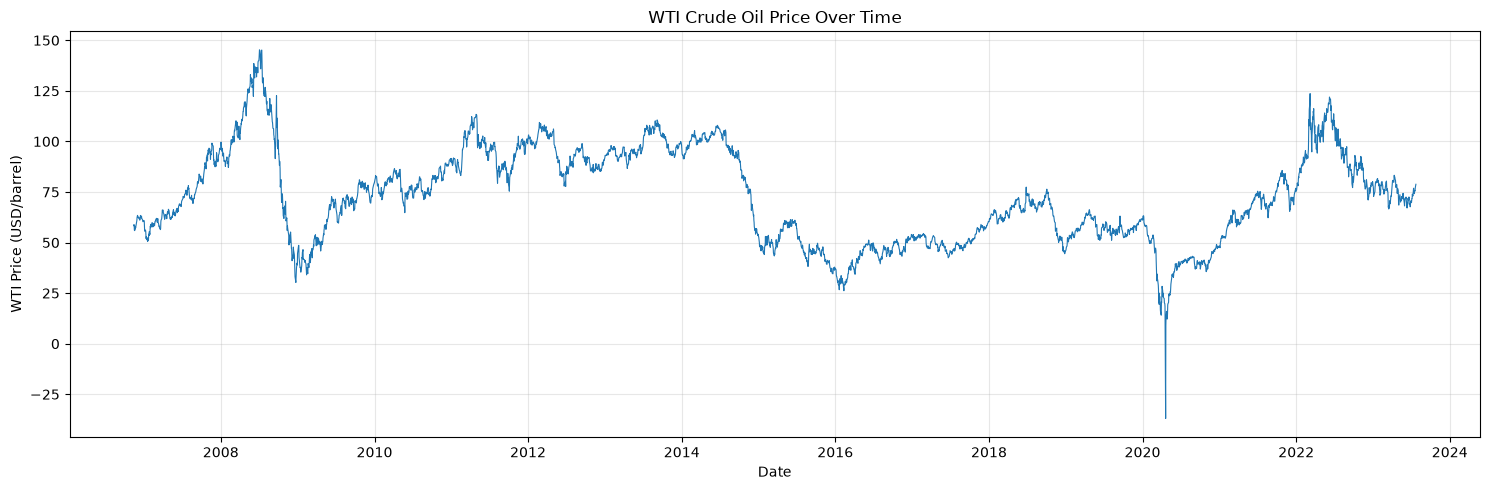

In [237]:
plt.figure(figsize=(15, 5))

plt.plot(
    data_multi_model["Date"],
    data_multi_model["wti"],
    linewidth=0.8
)

plt.title("WTI Crude Oil Price Over Time")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [238]:
# Sắp xếp dữ liệu theo thời gian
eda_data = data_multi_model.sort_values("Date").copy()

# Tính mức thay đổi giá WTI
eda_data["WTI_Change"] = eda_data["wti"].diff()

# Tính phần trăm thay đổi
# Chỉ dùng để tham khảo vì giá WTI có thể âm hoặc gần 0
eda_data["WTI_Pct_Change"] = (
    eda_data["wti"].pct_change() * 100
)

print(eda_data[[
    "Date", "wti", "WTI_Change", "WTI_Pct_Change"
]].head(10))

        Date    wti  WTI_Change  WTI_Pct_Change
0 2006-11-13  58.59         NaN             NaN
1 2006-11-14  58.28       -0.31       -0.529101
2 2006-11-15  58.79        0.51        0.875086
3 2006-11-16  56.23       -2.56       -4.354482
4 2006-11-17  55.90       -0.33       -0.586875
5 2006-11-20  56.42        0.52        0.930233
6 2006-11-21  58.01        1.59        2.818150
7 2006-11-22  57.28       -0.73       -1.258404
8 2006-11-27  60.30        3.02        5.272346
9 2006-11-28  60.97        0.67        1.111111


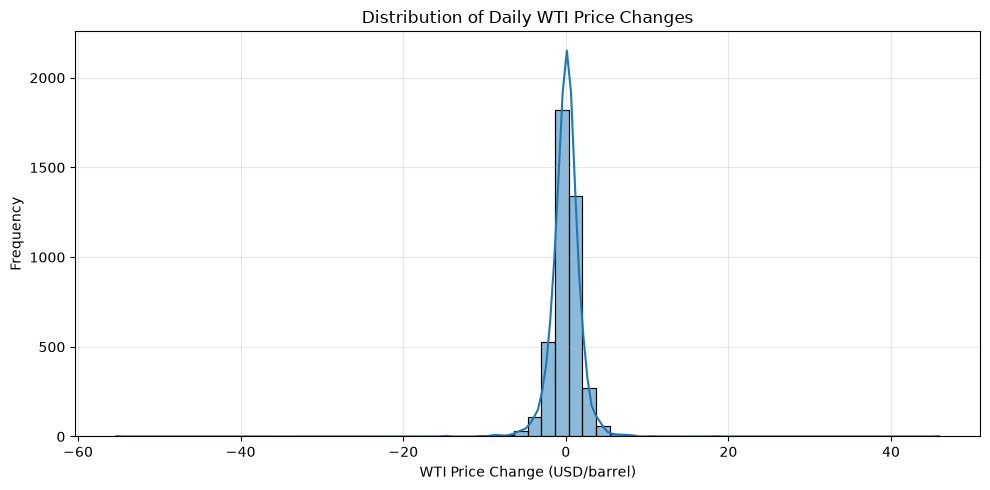

In [239]:
plt.figure(figsize=(10, 5))

sns.histplot(
    eda_data["WTI_Change"].dropna(),
    bins=60,
    kde=True
)

plt.title("Distribution of Daily WTI Price Changes")
plt.xlabel("WTI Price Change (USD/barrel)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

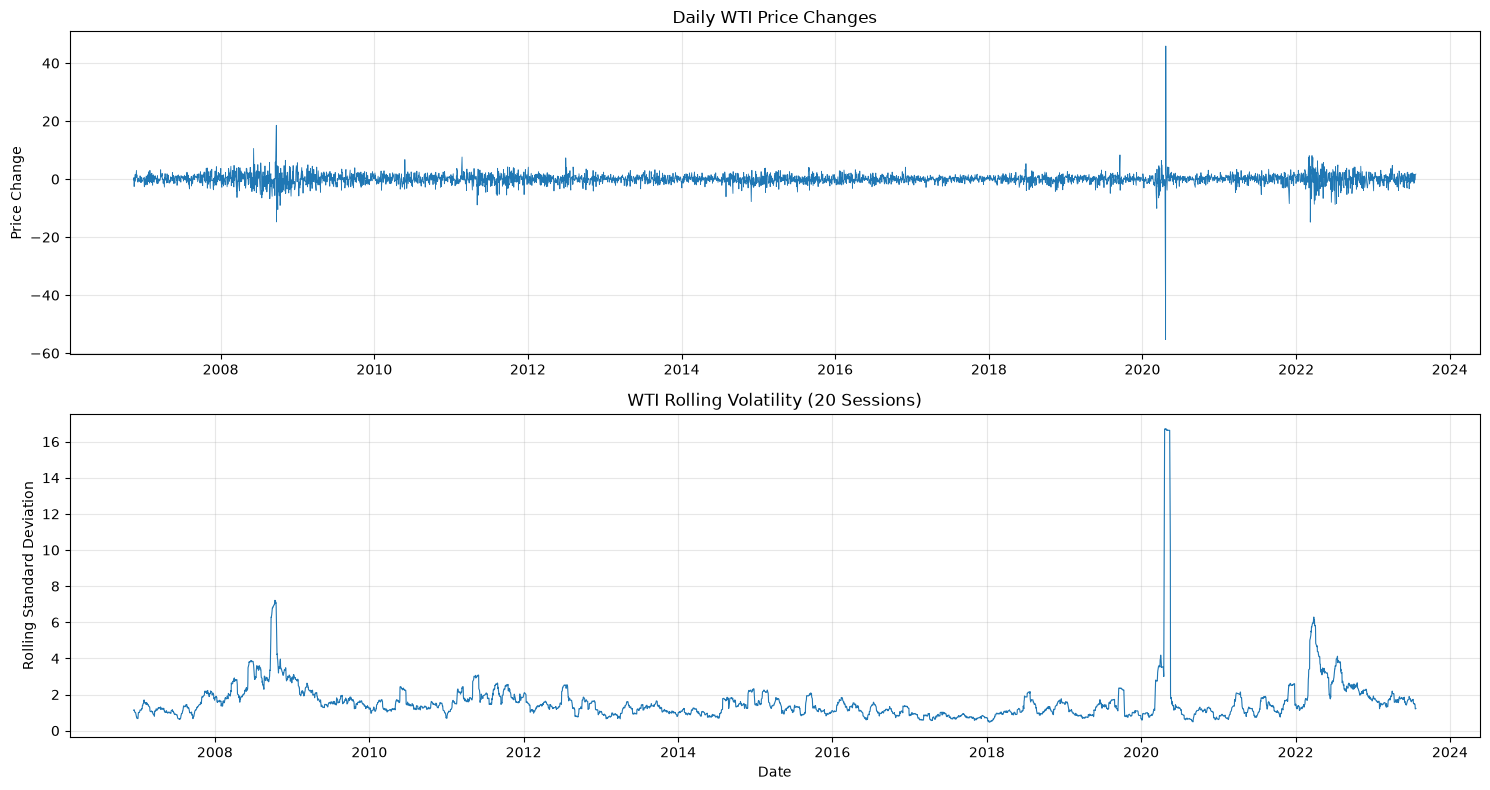

In [240]:
# Độ lệch chuẩn cuốn chiếu 20 phiên
eda_data["Rolling_Volatility_20"] = (
    eda_data["WTI_Change"].rolling(20).std()
)

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(
    eda_data["Date"],
    eda_data["WTI_Change"],
    linewidth=0.6
)
axes[0].set_title("Daily WTI Price Changes")
axes[0].set_ylabel("Price Change")
axes[0].grid(alpha=0.3)

axes[1].plot(
    eda_data["Date"],
    eda_data["Rolling_Volatility_20"],
    linewidth=0.8
)
axes[1].set_title("WTI Rolling Volatility (20 Sessions)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Rolling Standard Deviation")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [241]:
from statsmodels.tsa.stattools import adfuller, kpss

# Lấy chuỗi giá WTI và mức thay đổi giá
wti_price = eda_data["wti"].dropna()
wti_change = eda_data["WTI_Change"].dropna()

def stationarity_test(series, name):
    print(f"\n===== {name} =====")

    # ADF Test
    adf_result = adfuller(series, autolag="AIC")

    print("ADF Statistic:", round(adf_result[0], 4))
    print("ADF P-value:", round(adf_result[1], 6))

    # KPSS Test
    kpss_result = kpss(
        series,
        regression="c",
        nlags="auto"
    )

    print("KPSS Statistic:", round(kpss_result[0], 4))
    print("KPSS P-value:", round(kpss_result[1], 6))


# Kiểm tra chuỗi giá
stationarity_test(wti_price, "WTI Price")

# Kiểm tra chuỗi thay đổi giá
stationarity_test(wti_change, "WTI Price Change")


===== WTI Price =====


C:\Users\admin\AppData\Local\Temp\ipykernel_34540\1993000085.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")
C:\Users\admin\AppData\Local\Temp\ipykernel_34540\1993000085.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
C:\Users\admin\AppData\Local\Temp\ipykernel_34540\1993000085.py:17: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever i

ADF Statistic: -2.8262
ADF P-value: 0.054627
KPSS Statistic: 1.8515
KPSS P-value: 0.01

===== WTI Price Change =====
ADF Statistic: -10.4582
ADF P-value: 0.0
KPSS Statistic: 0.0552
KPSS P-value: 0.1


C:\Users\admin\AppData\Local\Temp\ipykernel_34540\1993000085.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")
C:\Users\admin\AppData\Local\Temp\ipykernel_34540\1993000085.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
C:\Users\admin\AppData\Local\Temp\ipykernel_34540\1993000085.py:17: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever i

In [242]:
from statsmodels.stats.diagnostic import het_arch

# Lấy chuỗi thay đổi giá WTI
wti_change_clean = eda_data["WTI_Change"].dropna()

# ARCH-LM Test
arch_result = het_arch(
    wti_change_clean,
    nlags=10
)

lm_stat, lm_pvalue, f_stat, f_pvalue = arch_result

print("ARCH-LM Statistic:", lm_stat)
print("ARCH-LM P-value:", lm_pvalue)
print("F Statistic:", f_stat)
print("F P-value:", f_pvalue)

ARCH-LM Statistic: 1286.5427167094774
ARCH-LM P-value: 3.068096734198271e-270
F Statistic: 185.29152397827895
F P-value: 0.0


C:\Users\admin\Energy_Forecasting_XAI\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


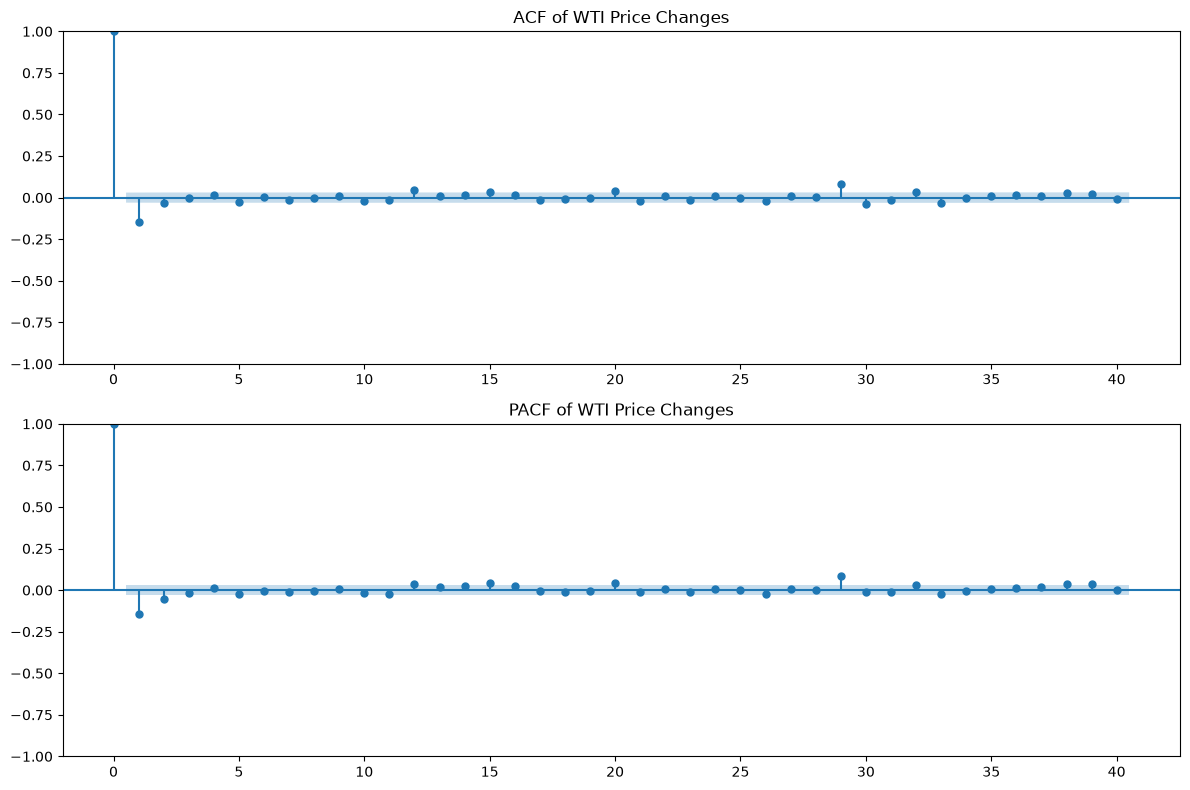

In [243]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# ACF của mức thay đổi giá
plot_acf(
    wti_change_clean,
    lags=40,
    ax=axes[0]
)

axes[0].set_title("ACF of WTI Price Changes")

# PACF của mức thay đổi giá
plot_pacf(
    wti_change_clean,
    lags=40,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF of WTI Price Changes")

plt.tight_layout()
plt.show()

<Figure size 1200x400 with 0 Axes>

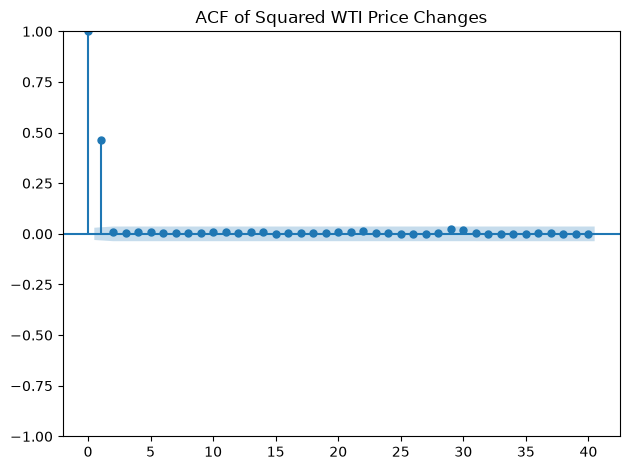

In [244]:
# Bình phương mức thay đổi giá
wti_change_squared = wti_change_clean ** 2

plt.figure(figsize=(12, 4))

plot_acf(
    wti_change_squared,
    lags=40
)

plt.title("ACF of Squared WTI Price Changes")
plt.tight_layout()
plt.show()

In [245]:
%pip install arch

Note: you may need to restart the kernel to use updated packages.


In [246]:
from arch import arch_model

# Sử dụng mức thay đổi giá WTI
# Nhân 100 để đưa dữ liệu về thang đo thuận tiện hơn
wti_returns = wti_change_clean * 100

# GARCH(1,1), giả định phân phối Student-t
garch_model = arch_model(
    wti_returns,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_result = garch_model.fit(
    update_freq=0,
    disp="off"
)

print(garch_result.summary())

C:\Users\admin\Energy_Forecasting_XAI\.venv\Lib\site-packages\arch\univariate\base.py:1134: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 4.161e+04. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


                              AR - GARCH Model Results                              
Dep. Variable:                   WTI_Change   R-squared:                       0.003
Mean Model:                              AR   Adj. R-squared:                  0.003
Vol Model:                            GARCH   Log-Likelihood:               -26891.4
Distribution:      Standardized Student's t   AIC:                           53794.8
Method:                  Maximum Likelihood   BIC:                           53832.8
                                              No. Observations:                 4193
Date:                      Sun, Nov 22 2026   Df Residuals:                     4191
Time:                              00:31:49   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------------------------------------

In [247]:
from arch import arch_model

# Điều chỉnh thang đo
wti_returns_scaled = wti_change_clean * 10

# Xây dựng AR(1)-GARCH(1,1)
garch_model_scaled = arch_model(
    wti_returns_scaled,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

# Huấn luyện mô hình
garch_result_scaled = garch_model_scaled.fit(
    update_freq=0,
    disp="off"
)

print(garch_result_scaled.summary())

                              AR - GARCH Model Results                              
Dep. Variable:                   WTI_Change   R-squared:                       0.003
Mean Model:                              AR   Adj. R-squared:                  0.003
Vol Model:                            GARCH   Log-Likelihood:               -17236.7
Distribution:      Standardized Student's t   AIC:                           34485.3
Method:                  Maximum Likelihood   BIC:                           34523.4
                                              No. Observations:                 4193
Date:                      Sun, Nov 22 2026   Df Residuals:                     4191
Time:                              00:31:49   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------------------------------------

In [248]:
# Lấy phần dư chuẩn hóa
standardized_resid = garch_result_scaled.std_resid.dropna()

# Kiểm tra ARCH-LM trên phần dư chuẩn hóa
arch_resid_test = het_arch(
    standardized_resid,
    nlags=10
)

print("ARCH-LM Statistic:", arch_resid_test[0])
print("ARCH-LM P-value:", arch_resid_test[1])

ARCH-LM Statistic: 0.715642699339916
ARCH-LM P-value: 0.9999636743927712


C:\Users\admin\Energy_Forecasting_XAI\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


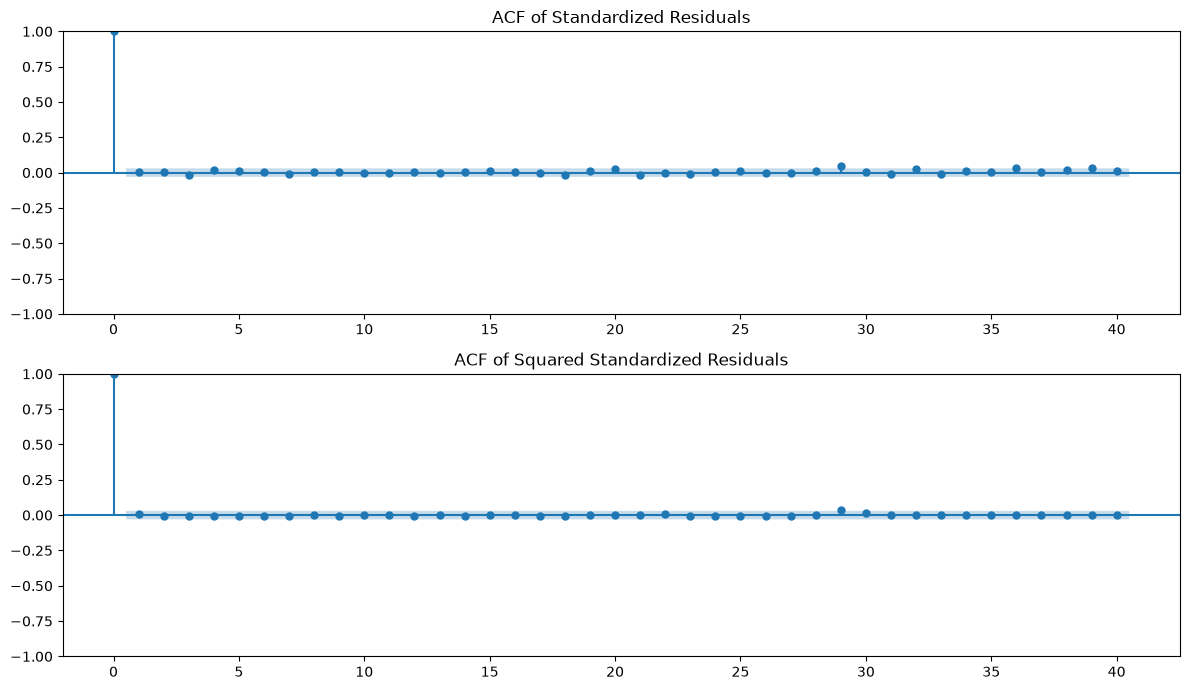

In [249]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

plot_acf(
    standardized_resid,
    lags=40,
    ax=axes[0]
)
axes[0].set_title("ACF of Standardized Residuals")

plot_acf(
    standardized_resid ** 2,
    lags=40,
    ax=axes[1]
)
axes[1].set_title("ACF of Squared Standardized Residuals")

plt.tight_layout()
plt.show()

In [250]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Kiểm tra tự tương quan phần dư chuẩn hóa
lb_residual = acorr_ljungbox(
    standardized_resid,
    lags=[10, 20],
    return_df=True
)

# Kiểm tra tự tương quan bình phương phần dư
lb_squared = acorr_ljungbox(
    standardized_resid ** 2,
    lags=[10, 20],
    return_df=True
)

print("Ljung-Box Test - Standardized Residuals")
print(lb_residual)

print("\nLjung-Box Test - Squared Standardized Residuals")
print(lb_squared)

Ljung-Box Test - Standardized Residuals
      lb_stat  lb_pvalue
10   4.503281   0.921801
20  10.455781   0.959135

Ljung-Box Test - Squared Standardized Residuals
     lb_stat  lb_pvalue
10  0.717906   0.999963
20  1.023508   1.000000


In [251]:
# GJR-GARCH(1,1) với phân phối Student-t
gjr_model = arch_model(
    wti_returns_scaled,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

gjr_result = gjr_model.fit(
    update_freq=0,
    disp="off"
)

print(gjr_result.summary())

                            AR - GJR-GARCH Model Results                            
Dep. Variable:                   WTI_Change   R-squared:                       0.003
Mean Model:                              AR   Adj. R-squared:                  0.003
Vol Model:                        GJR-GARCH   Log-Likelihood:               -17234.9
Distribution:      Standardized Student's t   AIC:                           34483.8
Method:                  Maximum Likelihood   BIC:                           34528.2
                                              No. Observations:                 4193
Date:                      Sun, Nov 22 2026   Df Residuals:                     4191
Time:                              00:31:53   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------------------------------------

In [252]:
# EGARCH(1,1) với phân phối Student-t
egarch_model = arch_model(
    wti_returns_scaled,
    mean="AR",
    lags=1,
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

egarch_result = egarch_model.fit(
    update_freq=0,
    disp="off"
)

print(egarch_result.summary())

                             AR - EGARCH Model Results                              
Dep. Variable:                   WTI_Change   R-squared:                       0.002
Mean Model:                              AR   Adj. R-squared:                  0.002
Vol Model:                           EGARCH   Log-Likelihood:               -17216.9
Distribution:      Standardized Student's t   AIC:                           34447.9
Method:                  Maximum Likelihood   BIC:                           34492.3
                                              No. Observations:                 4193
Date:                      Sun, Nov 22 2026   Df Residuals:                     4191
Time:                              00:31:54   Df Model:                            2
                                    Mean Model                                   
                     coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------

In [253]:
# Lấy phần dư chuẩn hóa của EGARCH
egarch_resid = egarch_result.std_resid.dropna()

# ARCH-LM Test
egarch_arch_test = het_arch(
    egarch_resid,
    nlags=10
)

print("EGARCH ARCH-LM Statistic:", egarch_arch_test[0])
print("EGARCH ARCH-LM P-value:", egarch_arch_test[1])

# Ljung-Box Test
egarch_lb = acorr_ljungbox(
    egarch_resid,
    lags=[10, 20],
    return_df=True
)

egarch_lb_squared = acorr_ljungbox(
    egarch_resid ** 2,
    lags=[10, 20],
    return_df=True
)

print("\nLjung-Box - Standardized Residuals")
print(egarch_lb)

print("\nLjung-Box - Squared Standardized Residuals")
print(egarch_lb_squared)

EGARCH ARCH-LM Statistic: 1.2627560453658804
EGARCH ARCH-LM P-value: 0.9995039312792332

Ljung-Box - Standardized Residuals
      lb_stat  lb_pvalue
10   4.723445   0.908870
20  11.639130   0.927937

Ljung-Box - Squared Standardized Residuals
     lb_stat  lb_pvalue
10  1.266188   0.999498
20  1.667825   1.000000


C:\Users\admin\Energy_Forecasting_XAI\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [254]:
# Chuẩn bị chuỗi thay đổi giá theo thời gian
garch_data = eda_data[
    ["Date", "WTI_Change"]
].dropna().copy()

# Chia dữ liệu theo thứ tự thời gian
split_idx = int(len(garch_data) * 0.8)

garch_train = garch_data.iloc[:split_idx].copy()
garch_test = garch_data.iloc[split_idx:].copy()

# Nhân 10 để điều chỉnh thang đo
train_returns = garch_train["WTI_Change"] * 10
test_returns = garch_test["WTI_Change"] * 10

print("Train observations:", len(train_returns))
print("Test observations:", len(test_returns))

print("\nTrain period:")
print(garch_train["Date"].min(), "to", garch_train["Date"].max())

print("\nTest period:")
print(garch_test["Date"].min(), "to", garch_test["Date"].max())

Train observations: 3355
Test observations: 839

Train period:
2006-11-14 00:00:00 to 2020-03-19 00:00:00

Test period:
2020-03-20 00:00:00 to 2023-07-24 00:00:00


In [255]:
from arch import arch_model
import pandas as pd
import numpy as np

# Ghép chuỗi Train và Test, giữ đúng thứ tự thời gian
all_returns = garch_data["WTI_Change"].reset_index(drop=True) * 10

# Xây dựng EGARCH trên toàn bộ chuỗi,
# nhưng chỉ ước lượng tham số đến hết Train
egarch_oos_model = arch_model(
    all_returns,
    mean="AR",
    lags=1,
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

egarch_oos_result = egarch_oos_model.fit(
    last_obs=split_idx,
    update_freq=0,
    disp="off"
)

# Dự báo phương sai một bước trước trên Test
egarch_forecast = egarch_oos_result.forecast(
    start=split_idx - 1,
    horizon=1,
    align="target",
    reindex=True
)

# Lấy phương sai dự báo tại 839 ngày Test
egarch_test_variance = (
    egarch_forecast.variance["h.1"]
    .iloc[split_idx:]
)

# Chuyển từ thang đo nhân 10 về đơn vị gốc
egarch_test_variance = egarch_test_variance / 100

# Độ lệch chuẩn có điều kiện
egarch_test_volatility = np.sqrt(
    egarch_test_variance
)

print("Number of forecasts:", egarch_test_volatility.notna().sum())
print("\nFirst 5 forecasts:")
print(egarch_test_volatility.dropna().head())

Number of forecasts: 839

First 5 forecasts:
3355    2.830377
3356    3.081523
3357    3.092443
3358    3.095642
3359    2.973945
Name: h.1, dtype: float64


In [256]:
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# Lấy 839 giá trị thực tế và 839 giá trị dự báo

# Bình phương biến động thực tế
realized_var = (
    garch_test["WTI_Change"]
    .reset_index(drop=True) ** 2
)

# Phương sai dự báo (đã chuyển về thang đo ban đầu)
forecast_var = (
    egarch_test_variance
    .reset_index(drop=True)
)

# Ghép hai chuỗi theo ngày, loại bỏ giá trị thiếu
evaluation = pd.DataFrame({
    "Realized_Variance": realized_var,
    "Forecast_Variance": forecast_var
}).dropna()

# RMSE
rmse_var = np.sqrt(mean_squared_error(
    evaluation["Realized_Variance"],
    evaluation["Forecast_Variance"]
))

# QLIKE
epsilon = 1e-10

qlike = np.mean(
    np.log(evaluation["Forecast_Variance"] + epsilon)
    + evaluation["Realized_Variance"]
    / (evaluation["Forecast_Variance"] + epsilon)
)

print("Số quan sát đánh giá:", len(evaluation))
print("RMSE (Variance):", rmse_var)
print("QLIKE:", qlike)

Số quan sát đánh giá: 839
RMSE (Variance): 126.83996555318309
QLIKE: 2.7575997401773953


In [257]:
from arch import arch_model

all_returns = (
    garch_data["WTI_Change"]
    .reset_index(drop=True) * 10
)

# GARCH(1,1)
garch_oos_model = arch_model(
    all_returns,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_oos_result = garch_oos_model.fit(
    last_obs=split_idx,
    update_freq=0,
    disp="off"
)

# GJR-GARCH(1,1)
gjr_oos_model = arch_model(
    all_returns,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

gjr_oos_result = gjr_oos_model.fit(
    last_obs=split_idx,
    update_freq=0,
    disp="off"
)

print("Đã huấn luyện xong GARCH và GJR-GARCH!")

Đã huấn luyện xong GARCH và GJR-GARCH!


In [258]:
# GARCH forecast
garch_forecast = garch_oos_result.forecast(
    start=split_idx - 1,
    horizon=1,
    align="target",
    reindex=True
)

garch_test_variance = (
    garch_forecast.variance["h.1"].iloc[split_idx:] / 100
)

# GJR-GARCH forecast
gjr_forecast = gjr_oos_result.forecast(
    start=split_idx - 1,
    horizon=1,
    align="target",
    reindex=True
)

gjr_test_variance = (
    gjr_forecast.variance["h.1"].iloc[split_idx:] / 100
)

print("GARCH:", garch_test_variance.notna().sum())
print("GJR-GARCH:", gjr_test_variance.notna().sum())

GARCH: 839
GJR-GARCH: 839


In [259]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

# Phương sai thực tế
realized_var = (
    garch_test["WTI_Change"]
    .reset_index(drop=True) ** 2
)

# Ghép các dự báo theo thứ tự quan sát
evaluation = pd.DataFrame({
    "Realized_Variance": realized_var,
    "GARCH": garch_test_variance.reset_index(drop=True),
    "GJR-GARCH": gjr_test_variance.reset_index(drop=True),
    "EGARCH": egarch_test_variance.reset_index(drop=True)
}).dropna()

# Hàm tính chỉ số
def evaluate_volatility(actual, predicted):
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    epsilon = 1e-10
    qlike = np.mean(
        np.log(predicted + epsilon)
        + actual / (predicted + epsilon)
    )

    return rmse, qlike

# Đánh giá từng mô hình
results = []

for model in ["GARCH", "GJR-GARCH", "EGARCH"]:
    rmse, qlike = evaluate_volatility(
        evaluation["Realized_Variance"],
        evaluation[model]
    )

    results.append({
        "Model": model,
        "RMSE": rmse,
        "QLIKE": qlike
    })

results_df = pd.DataFrame(results)

print("Số quan sát:", len(evaluation))
print(results_df.to_string(index=False))

Số quan sát: 839
    Model       RMSE    QLIKE
    GARCH 128.058779 2.845671
GJR-GARCH 127.668941 2.836489
   EGARCH 126.839966 2.757600


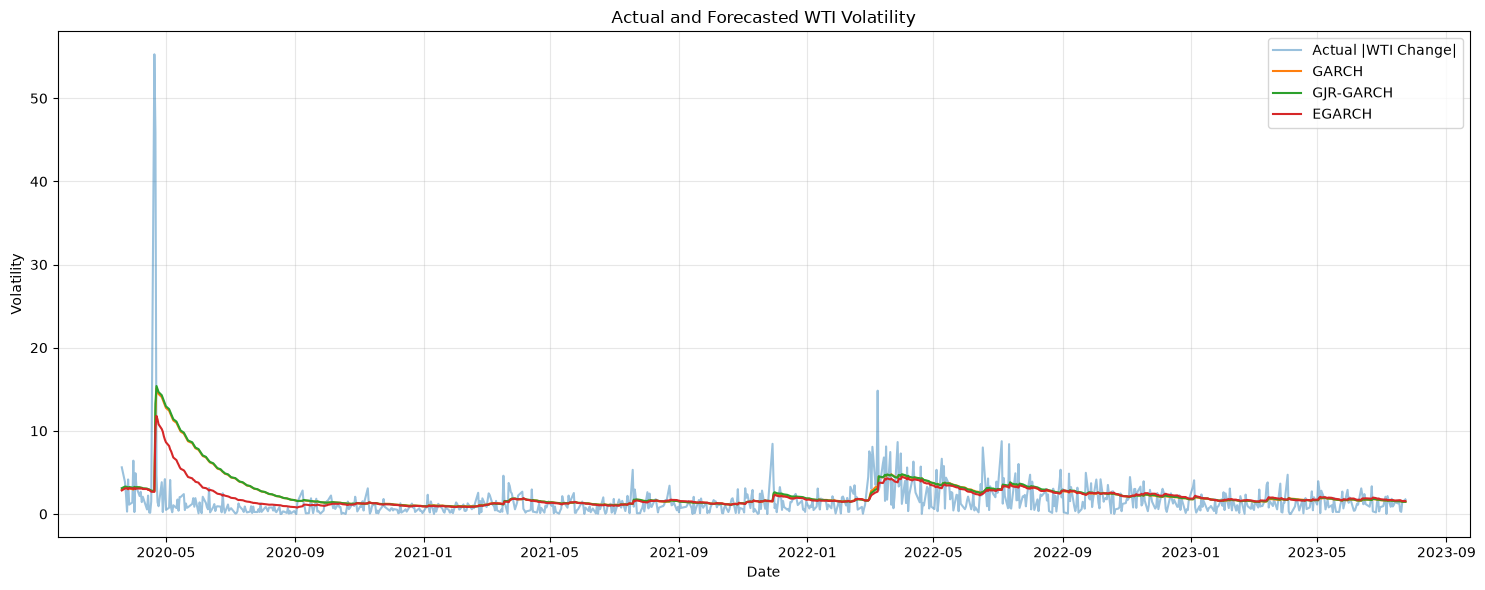

In [260]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plot_data = pd.DataFrame({
    "Date": garch_test["Date"].reset_index(drop=True),
    "Actual_Volatility": (
        garch_test["WTI_Change"].reset_index(drop=True).abs()
    ),
    "GARCH": np.sqrt(
        garch_test_variance.reset_index(drop=True)
    ),
    "GJR-GARCH": np.sqrt(
        gjr_test_variance.reset_index(drop=True)
    ),
    "EGARCH": np.sqrt(
        egarch_test_variance.reset_index(drop=True)
    )
})

plt.figure(figsize=(15, 6))

plt.plot(
    plot_data["Date"],
    plot_data["Actual_Volatility"],
    label="Actual |WTI Change|",
    alpha=0.45
)

plt.plot(
    plot_data["Date"],
    plot_data["GARCH"],
    label="GARCH"
)

plt.plot(
    plot_data["Date"],
    plot_data["GJR-GARCH"],
    label="GJR-GARCH"
)

plt.plot(
    plot_data["Date"],
    plot_data["EGARCH"],
    label="EGARCH"
)

plt.title("Actual and Forecasted WTI Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [261]:
import numpy as np
import pandas as pd

epsilon = 1e-10

actual_var = evaluation["Realized_Variance"]

# Tính QLIKE loss từng ngày cho từng mô hình
qlike_losses = pd.DataFrame(index=evaluation.index)

for model in ["GARCH", "GJR-GARCH", "EGARCH"]:
    predicted_var = evaluation[model].clip(lower=epsilon)

    qlike_losses[model] = (
        np.log(predicted_var)
        + actual_var / predicted_var
    )

print("QLIKE loss trung bình:")
print(qlike_losses.mean())

QLIKE loss trung bình:
GARCH        2.845671
GJR-GARCH    2.836489
EGARCH       2.757600
dtype: float64


In [262]:
import statsmodels.api as sm
from itertools import combinations

pairs = [
    ("GARCH", "EGARCH"),
    ("GJR-GARCH", "EGARCH"),
    ("GARCH", "GJR-GARCH")
]

dm_results = []

for model_a, model_b in pairs:

    # Chênh lệch QLIKE loss
    loss_diff = (
        qlike_losses[model_a] - qlike_losses[model_b]
    )

    # Kiểm định trung bình bằng OLS + Newey-West HAC
    X = np.ones((len(loss_diff), 1))

    dm_model = sm.OLS(loss_diff.values, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 10}
    )

    dm_results.append({
        "Comparison": f"{model_a} vs {model_b}",
        "Mean_Loss_Diff": loss_diff.mean(),
        "DM_Statistic": dm_model.tvalues[0],
        "P_Value": dm_model.pvalues[0]
    })

dm_results_df = pd.DataFrame(dm_results)

print(dm_results_df.to_string(index=False))

         Comparison  Mean_Loss_Diff  DM_Statistic  P_Value
    GARCH vs EGARCH        0.088071      1.543104 0.122805
GJR-GARCH vs EGARCH        0.078889      1.187631 0.234979
 GARCH vs GJR-GARCH        0.009182      0.415333 0.677898


In [263]:
%pip install lime

Note: you may need to restart the kernel to use updated packages.


In [264]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd

In [265]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train_multi[features_e5].values,
    feature_names=features_e5,
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

print("Đã khởi tạo LIME Explainer!")

Đã khởi tạo LIME Explainer!


In [266]:
X_test_e5 = X_test_multi[features_e5].copy()

sample_index = 0

sample = X_test_e5.iloc[sample_index].values

def predict_fn(data):
    data_df = pd.DataFrame(
        data,
        columns=features_e5
    )

    return best_model_e5.predict(data_df)

lime_exp = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=predict_fn,
    num_features=10
)

print("Giải thích LIME cho quan sát:", sample_index)
print("Các đặc trưng ảnh hưởng:")
print(lime_exp.as_list())

Giải thích LIME cho quan sát: 0
Các đặc trưng ảnh hưởng:
[('SRV_Lag1 > 0.00', -0.17006963759650798), ('EPI_Lag5 > 133.25', -0.1297705660344177), ('wti_Lag1 <= 53.30', 0.09369316225285892), ('EPI_Lag2 > 133.46', 0.06000371619050037), ('0.18 < TB_Lag3 <= 1.58', -0.05847499981972807), ('wti_Lag20 <= 53.55', -0.04576960742202879), ('EPI_Lag1 > 133.56', -0.04012933947474929), ('SRV_Lag2 > 0.00', -0.039974390523872506), ('wti_Lag5 <= 53.33', 0.03668467841447384), ('SRV_Lag3 > 0.00', 0.0360750264101491)]


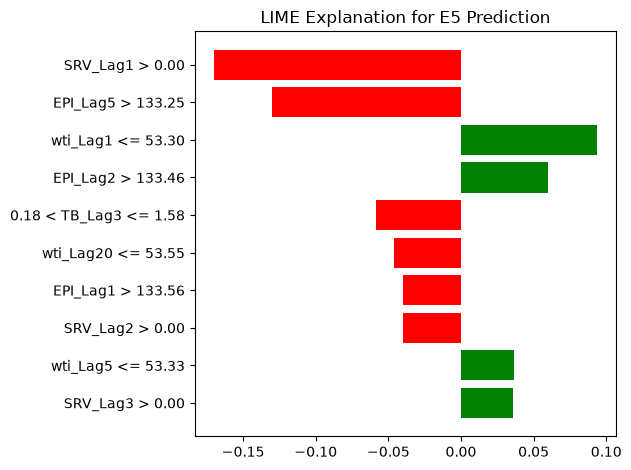

In [267]:
import matplotlib.pyplot as plt

lime_exp.as_pyplot_figure()

plt.title("LIME Explanation for E5 Prediction")
plt.tight_layout()
plt.show()

In [268]:
print("LIME local fidelity score:", lime_exp.score)

print("\nLIME local prediction:")
print(lime_exp.local_pred)

print("\nLIME intercept:")
print(lime_exp.intercept)

print("\nXGBoost prediction:")
print(best_model_e5.predict(
    X_test_e5.iloc[[sample_index]]
))

LIME local fidelity score: 0.09462056075848202

LIME local prediction:
[-0.25054078]

LIME intercept:
{0: np.float64(0.007191180587788101), 1: np.float64(0.007191180587788101)}

XGBoost prediction:
[0.39988482]


In [269]:
lime_exp_2 = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=predict_fn,
    num_features=10,
    num_samples=10000
)

print("Fidelity score:", lime_exp_2.score)
print("LIME prediction:", lime_exp_2.local_pred)

print("XGBoost prediction:",
      best_model_e5.predict(
          X_test_e5.iloc[[sample_index]]
      ))

print("\nCác đặc trưng quan trọng:")
print(lime_exp_2.as_list())

Fidelity score: 0.08840089310984622
LIME prediction: [-0.34607037]
XGBoost prediction: [0.39988482]

Các đặc trưng quan trọng:
[('SRV_Lag1 > 0.00', -0.1817654258530602), ('EPI_Lag5 > 133.25', -0.1355431020498174), ('wti_Lag1 <= 53.30', 0.08073358424019307), ('EPI_Lag1 > 133.56', -0.06275051883585318), ('EPI_Lag2 > 133.46', 0.04721343427354914), ('wti_Lag20 <= 53.55', -0.047133981754088415), ('SRV_Lag2 > 0.00', -0.043643232111654995), ('0.18 < TB_Lag3 <= 1.58', -0.03801390266816341), ('EPI_Lag3 > 133.41', -0.03419413306644016), ('TB_Lag1 <= 0.06', 0.028425890322468422)]


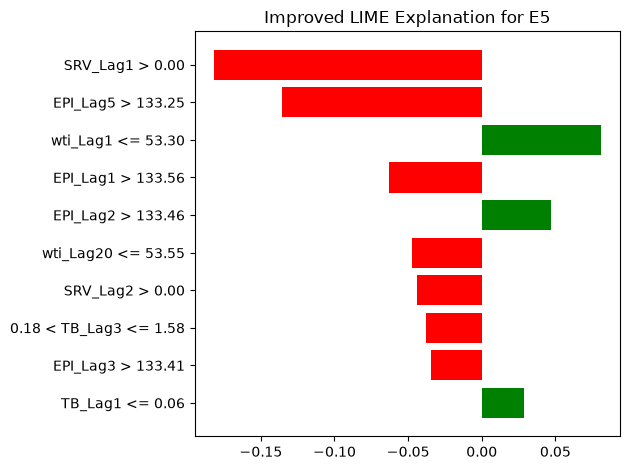

In [270]:
lime_exp_2.as_pyplot_figure()

plt.title("Improved LIME Explanation for E5")
plt.tight_layout()
plt.show()

In [271]:
print("Fidelity score:", lime_exp_2.score)

print("LIME local prediction:",
      lime_exp_2.local_pred)

print("XGBoost prediction:",
      best_model_e5.predict(
          X_test_e5.iloc[[sample_index]]
      ))

Fidelity score: 0.08840089310984622
LIME local prediction: [-0.34607037]
XGBoost prediction: [0.39988482]


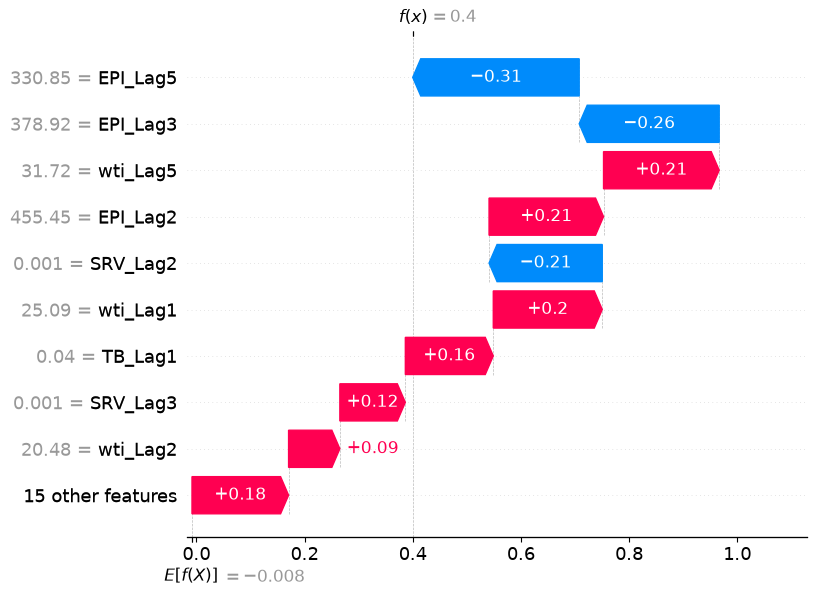

In [272]:
import shap

# Tạo SHAP TreeExplainer cho E5
shap_explainer_e5 = shap.TreeExplainer(best_model_e5)

# Chọn đúng quan sát đã giải thích bằng LIME
sample_df = X_test_e5.iloc[[sample_index]]

# Tính SHAP value
shap_values_local = shap_explainer_e5(
    sample_df
)

# Vẽ Waterfall Plot
shap.plots.waterfall(
    shap_values_local[0],
    max_display=10
)

Đang giải thích quan sát: 0


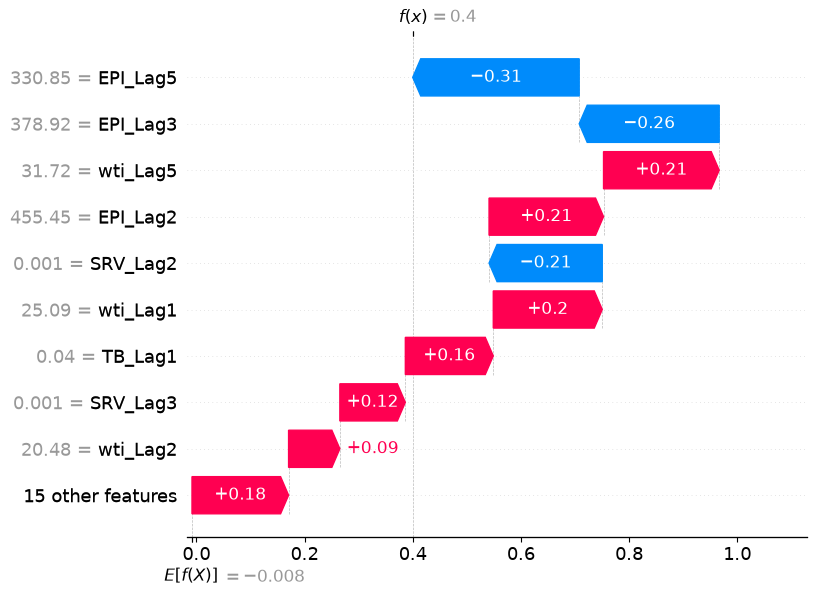

Đang giải thích quan sát: 419


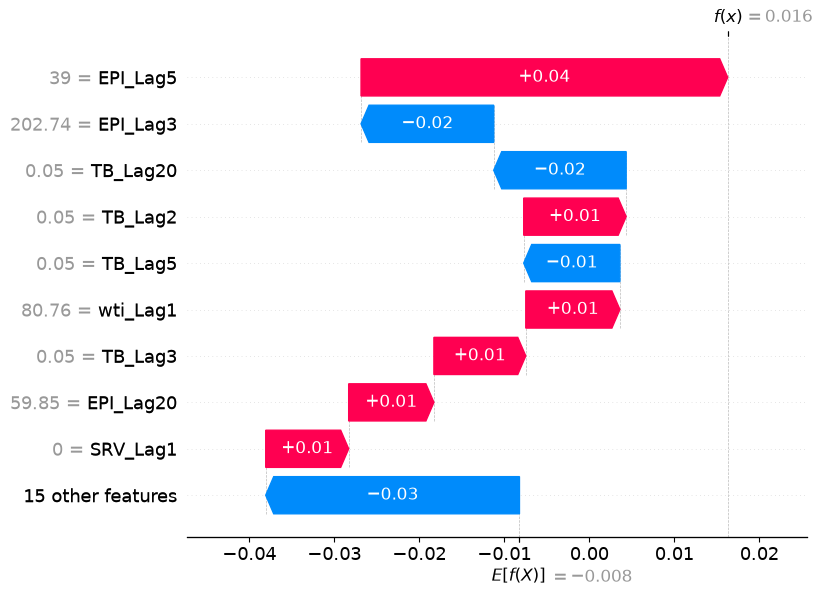

Đang giải thích quan sát: 20


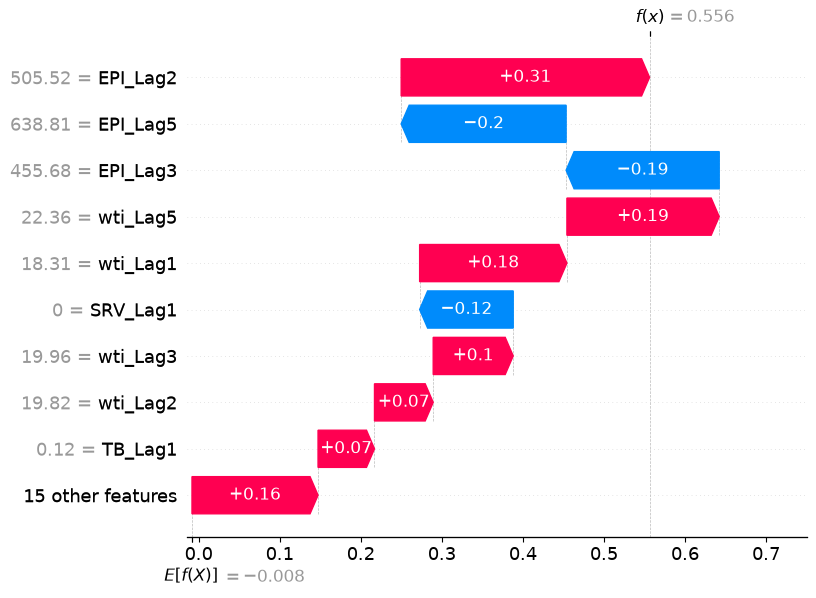

In [273]:
# Chọn 3 thời điểm đại diện
sample_indices = [
    0,
    len(X_test_e5) // 2,
    garch_test["WTI_Change"].abs().values.argmax()
]

for idx in sample_indices:
    print(f"Đang giải thích quan sát: {idx}")

    sample_df = X_test_e5.iloc[[idx]]

    shap_local = shap_explainer_e5(sample_df)

    shap.plots.waterfall(
        shap_local[0],
        max_display=10,
        show=True
    )

In [274]:
# Ba quan sát đã phân tích
sample_indices = [0, 419, 20]

for idx in sample_indices:

    actual_change = garch_test["WTI_Change"].iloc[idx]

    predicted_change = best_model_e5.predict(
        X_test_e5.iloc[[idx]]
    )[0]

    previous_price = X_test_e5["wti_Lag1"].iloc[idx]

    actual_price = previous_price + actual_change
    predicted_price = previous_price + predicted_change

    print(f"\n--- Quan sát {idx} ---")
    print("Ngày:", garch_test["Date"].iloc[idx])
    print("WTI Change thực tế:", actual_change)
    print("WTI Change dự báo:", predicted_change)
    print("Giá WTI thực tế:", actual_price)
    print("Giá WTI dự báo:", predicted_price)
    print("Sai số tuyệt đối:", abs(actual_price - predicted_price))


--- Quan sát 0 ---
Ngày: 2020-03-20 00:00:00
WTI Change thực tế: -5.609999999999999
WTI Change dự báo: 0.39988482
Giá WTI thực tế: 19.48
Giá WTI dự báo: 25.489884819984436
Sai số tuyệt đối: 6.0098848199844355

--- Quan sát 419 ---
Ngày: 2021-11-17 00:00:00
WTI Change thực tế: -2.440000000000012
WTI Change dự báo: 0.016276935
Giá WTI thực tế: 78.32
Giá WTI dự báo: 80.77627693511546
Sai số tuyệt đối: 2.4562769351154685

--- Quan sát 20 ---
Ngày: 2020-04-20 00:00:00
WTI Change thực tế: -55.28999999999999
WTI Change dự báo: 0.5562455
Giá WTI thực tế: -36.97999999999999
Giá WTI dự báo: 18.866245505809783
Sai số tuyệt đối: 55.846245505809776


In [275]:
# Dự báo WTI Change trên toàn bộ tập test
all_predictions = best_model_e5.predict(X_test_e5)

actual_changes = (
    garch_test["WTI_Change"]
    .reset_index(drop=True)
    .values
)

# Sai số tuyệt đối
absolute_errors = np.abs(
    actual_changes - all_predictions
)

# Vị trí dự báo tốt nhất và tệ nhất
best_idx = np.argmin(absolute_errors)
worst_idx = np.argmax(absolute_errors)

# Tạo bảng kết quả
for idx in [best_idx, worst_idx]:

    previous_price = X_test_e5["wti_Lag1"].iloc[idx]

    print(f"\n--- Quan sát {idx} ---")
    print("Ngày:", garch_test["Date"].iloc[idx])
    print("WTI Change thực tế:", actual_changes[idx])
    print("WTI Change dự báo:", all_predictions[idx])
    print("WTI thực tế:", previous_price + actual_changes[idx])
    print("WTI dự báo:", previous_price + all_predictions[idx])
    print("Sai số tuyệt đối:", absolute_errors[idx])


--- Quan sát 232 ---
Ngày: 2021-02-23 00:00:00
WTI Change thực tế: -0.010000000000005116
WTI Change dự báo: -0.0144773405
WTI thực tế: 61.66
WTI dự báo: 61.655522659495475
Sai số tuyệt đối: 0.004477340504521976

--- Quan sát 20 ---
Ngày: 2020-04-20 00:00:00
WTI Change thực tế: -55.28999999999999
WTI Change dự báo: 0.5562455
WTI thực tế: -36.97999999999999
WTI dự báo: 18.866245505809783
Sai số tuyệt đối: 55.846245505809776



Best Prediction - Observation 232


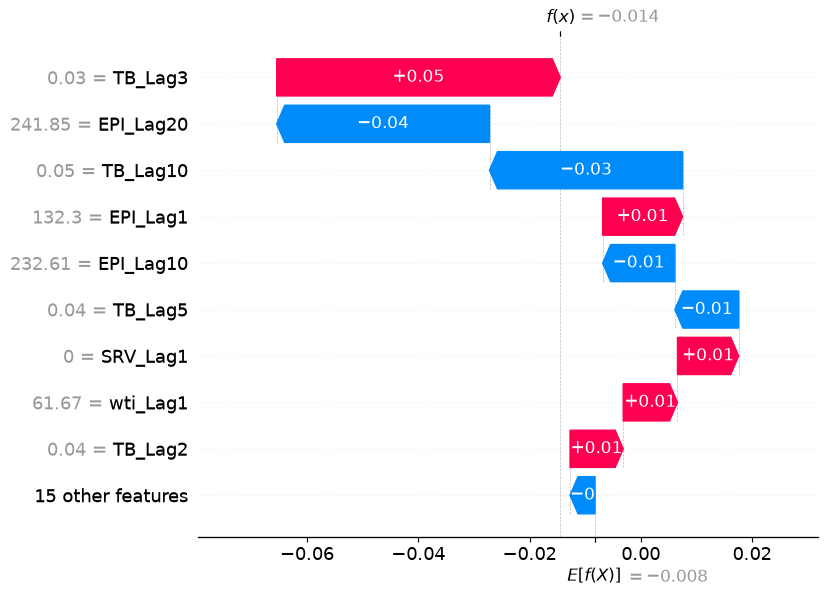


Worst Prediction - Observation 20


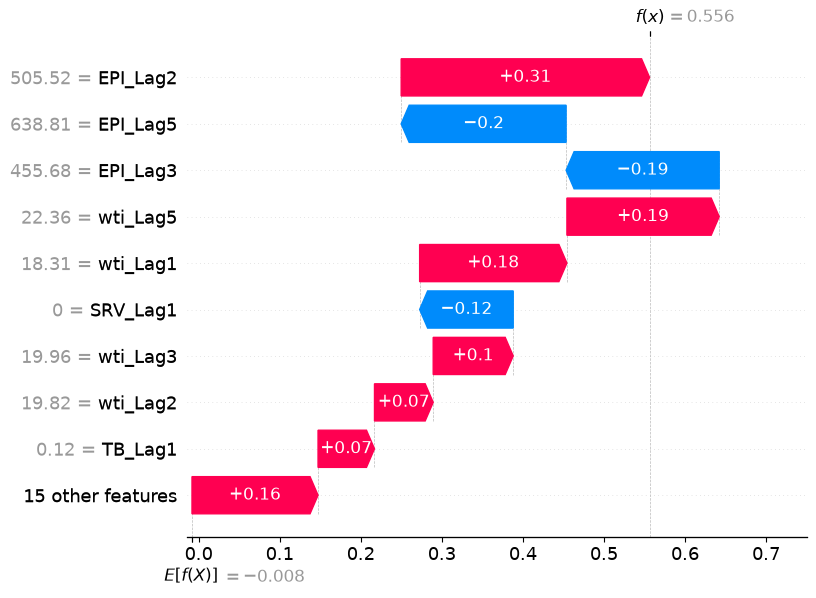

In [276]:
# Hai quan sát cần giải thích
selected_indices = {
    "Best Prediction": 232,
    "Worst Prediction": 20
}

for label, idx in selected_indices.items():

    sample_df = X_test_e5.iloc[[idx]]

    shap_local = shap_explainer_e5(sample_df)

    print(f"\n{label} - Observation {idx}")

    shap.plots.waterfall(
        shap_local[0],
        max_display=10
    )

In [277]:
# Độ lớn biến động thực tế trong tập test
volatility = (
    garch_test["WTI_Change"]
    .reset_index(drop=True)
    .abs()
)

# Ngưỡng phân vị
low_threshold = volatility.quantile(0.25)
high_threshold = volatility.quantile(0.75)

# Xác định hai nhóm
low_mask = volatility <= low_threshold
high_mask = volatility >= high_threshold

print("Ngưỡng biến động thấp:", low_threshold)
print("Ngưỡng biến động cao:", high_threshold)

print("\nSố quan sát biến động thấp:", low_mask.sum())
print("Số quan sát biến động cao:", high_mask.sum())

Ngưỡng biến động thấp: 0.48999999999999666
Ngưỡng biến động cao: 1.9100000000000037

Số quan sát biến động thấp: 210
Số quan sát biến động cao: 210


In [278]:
# Tính SHAP values cho 839 quan sát
shap_values_test = shap_explainer_e5(X_test_e5)

# Chuyển thành DataFrame
shap_values_df = pd.DataFrame(
    shap_values_test.values,
    columns=features_e5
)

print("Kích thước SHAP:", shap_values_df.shape)

Kích thước SHAP: (839, 24)


In [279]:
# Tách SHAP theo hai nhóm
shap_low = shap_values_df.loc[low_mask]
shap_high = shap_values_df.loc[high_mask]

# Mean Absolute SHAP
importance_low = shap_low.abs().mean()
importance_high = shap_high.abs().mean()

# Bảng so sánh
comparison = pd.DataFrame({
    "Low_Volatility": importance_low,
    "High_Volatility": importance_high
})

comparison["Difference"] = (
    comparison["High_Volatility"]
    - comparison["Low_Volatility"]
)

comparison = comparison.sort_values(
    "High_Volatility",
    ascending=False
)

print(comparison.to_string())

           Low_Volatility  High_Volatility  Difference
wti_Lag1         0.040665         0.089793    0.049128
SRV_Lag1         0.028284         0.067313    0.039029
EPI_Lag5         0.061393         0.058077   -0.003316
wti_Lag5         0.022264         0.048754    0.026490
EPI_Lag3         0.041079         0.046159    0.005080
EPI_Lag2         0.032327         0.042082    0.009755
wti_Lag20        0.006625         0.037053    0.030428
EPI_Lag1         0.018638         0.034493    0.015855
SRV_Lag10        0.012502         0.031339    0.018837
wti_Lag10        0.015978         0.028362    0.012384
wti_Lag3         0.014180         0.027645    0.013466
SRV_Lag2         0.008981         0.021951    0.012970
TB_Lag1          0.011774         0.019167    0.007392
wti_Lag2         0.014246         0.018805    0.004559
EPI_Lag20        0.018431         0.018196   -0.000235
TB_Lag2          0.013494         0.014418    0.000924
SRV_Lag3         0.004474         0.013486    0.009012
TB_Lag10  

In [280]:
feature_groups = {
    "WTI": [f for f in features_e5 if f.startswith("wti_")],
    "EPI": [f for f in features_e5 if f.startswith("EPI_")],
    "SRV": [f for f in features_e5 if f.startswith("SRV_")],
    "TB": [f for f in features_e5 if f.startswith("TB_")]
}

group_comparison = pd.DataFrame({
    "Low_Volatility": {
        group: shap_values_df.loc[low_mask, cols].abs().values.mean()
        for group, cols in feature_groups.items()
    },
    "High_Volatility": {
        group: shap_values_df.loc[high_mask, cols].abs().values.mean()
        for group, cols in feature_groups.items()
    }
})

group_comparison["Difference"] = (
    group_comparison["High_Volatility"]
    - group_comparison["Low_Volatility"]
)

print(group_comparison)

     Low_Volatility  High_Volatility  Difference
WTI        0.018993         0.041735    0.022742
EPI        0.029899         0.034276    0.004377
SRV        0.011083         0.024748    0.013665
TB         0.013406         0.013166   -0.000240


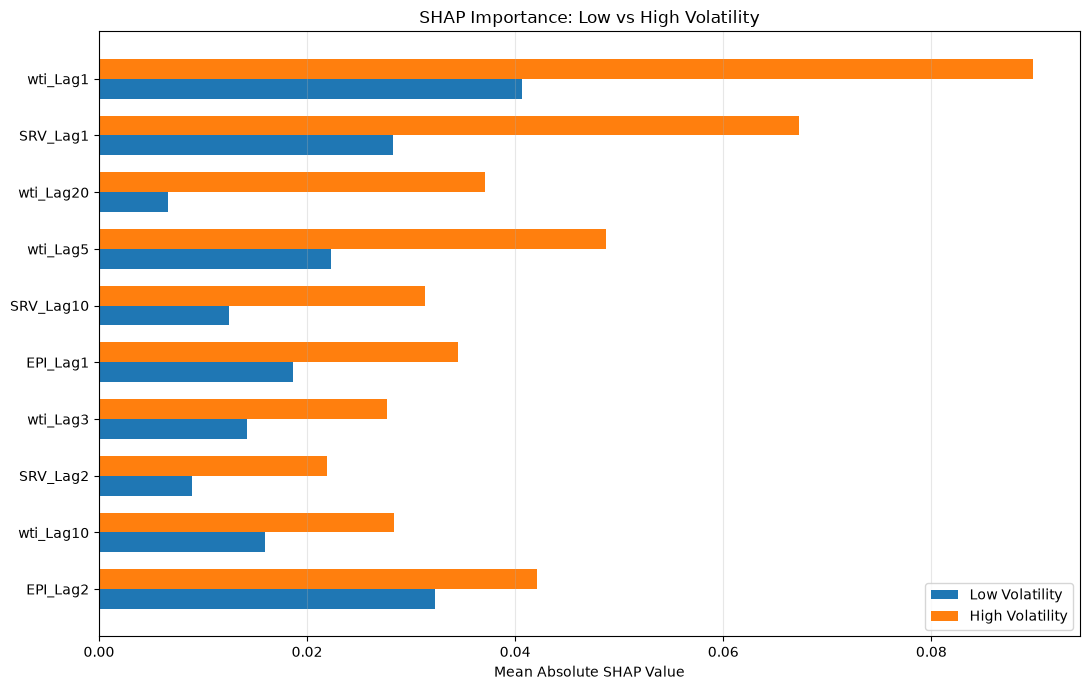

In [281]:
import matplotlib.pyplot as plt
import numpy as np

# Chọn 10 đặc trưng có chênh lệch SHAP tuyệt đối lớn nhất
top_features = (
    comparison["Difference"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

plot_comparison = comparison.loc[top_features].sort_values(
    "Difference"
)

y = np.arange(len(plot_comparison))
height = 0.35

plt.figure(figsize=(11, 7))

plt.barh(
    y - height/2,
    plot_comparison["Low_Volatility"],
    height,
    label="Low Volatility"
)

plt.barh(
    y + height/2,
    plot_comparison["High_Volatility"],
    height,
    label="High Volatility"
)

plt.yticks(y, plot_comparison.index)
plt.xlabel("Mean Absolute SHAP Value")
plt.title("SHAP Importance: Low vs High Volatility")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [282]:
import numpy as np
import pandas as pd

# Lấy giá trị SHAP tuyệt đối
abs_shap = np.abs(shap_values_df.values)

# Chuyển mask sang numpy
low_labels = low_mask.values
high_labels = high_mask.values

# Nhãn trạng thái thị trường
regime_labels = low_labels.astype(int) - high_labels.astype(int)

# Kiểm tra
print("Tổng số quan sát:", len(abs_shap))
print("Biến động thấp:", low_labels.sum())
print("Biến động cao:", high_labels.sum())
print("Số đặc trưng:", abs_shap.shape[1])

Tổng số quan sát: 839
Biến động thấp: 210
Biến động cao: 210
Số đặc trưng: 24


In [283]:
# Cấu hình Bootstrap
B = 1000
block_length = 10
n = len(abs_shap)

rng = np.random.default_rng(42)

# Lưu kết quả
bootstrap_results = {
    group: []
    for group in feature_groups
}

for b in range(B):

    sampled_indices = []

    # Lấy các block liên tiếp
    while len(sampled_indices) < n:
        start = rng.integers(0, n)

        block = [
            (start + j) % n
            for j in range(block_length)
        ]

        sampled_indices.extend(block)

    sampled_indices = np.array(sampled_indices[:n])

    # Dữ liệu Bootstrap
    sampled_shap = abs_shap[sampled_indices]
    sampled_regime = regime_labels[sampled_indices]

    for group, cols in feature_groups.items():

        feature_indices = [
            features_e5.index(col)
            for col in cols
        ]

        group_values = sampled_shap[:, feature_indices].mean(axis=1)

        low_values = group_values[sampled_regime == 1]
        high_values = group_values[sampled_regime == -1]

        difference = high_values.mean() - low_values.mean()

        bootstrap_results[group].append(difference)

print("Hoàn thành", B, "lần Bootstrap!")

Hoàn thành 1000 lần Bootstrap!


In [284]:
bootstrap_summary = []

for group, values in bootstrap_results.items():

    values = np.array(values)

    observed_diff = (
        group_comparison.loc[group, "High_Volatility"]
        - group_comparison.loc[group, "Low_Volatility"]
    )

    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)

    bootstrap_summary.append({
        "Group": group,
        "Observed_Difference": observed_diff,
        "CI_Lower_95%": lower,
        "CI_Upper_95%": upper,
        "Bootstrap_Mean": values.mean()
    })

bootstrap_df = pd.DataFrame(bootstrap_summary)

print(bootstrap_df.to_string(index=False))

Group  Observed_Difference  CI_Lower_95%  CI_Upper_95%  Bootstrap_Mean
  WTI             0.022742      0.010986      0.035699        0.022504
  EPI             0.004377     -0.004755      0.013581        0.004287
  SRV             0.013665      0.007898      0.019680        0.013546
   TB            -0.000240     -0.002562      0.002478       -0.000205


In [285]:
block_lengths = [5, 10, 20]
B = 1000

sensitivity_results = []

for L in block_lengths:

    rng = np.random.default_rng(42)

    for group, cols in feature_groups.items():

        feature_indices = [
            features_e5.index(col) for col in cols
        ]

        group_values = abs_shap[:, feature_indices].mean(axis=1)

        boot_diffs = []

        for b in range(B):
            sampled_indices = []

            while len(sampled_indices) < n:
                start = rng.integers(0, n)
                block = [(start + j) % n for j in range(L)]
                sampled_indices.extend(block)

            idx = np.array(sampled_indices[:n])
            labels = regime_labels[idx]
            values = group_values[idx]

            diff = (
                values[labels == -1].mean()
                - values[labels == 1].mean()
            )

            boot_diffs.append(diff)

        sensitivity_results.append({
            "Block_Length": L,
            "Group": group,
            "CI_Lower": np.percentile(boot_diffs, 2.5),
            "CI_Upper": np.percentile(boot_diffs, 97.5)
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

print(sensitivity_df.to_string(index=False))

 Block_Length Group  CI_Lower  CI_Upper
            5   WTI  0.012345  0.033342
            5   EPI -0.003437  0.012207
            5   SRV  0.008488  0.019189
            5    TB -0.002431  0.001803
           10   WTI  0.010986  0.035699
           10   EPI -0.004985  0.013037
           10   SRV  0.008120  0.020326
           10    TB -0.002847  0.002251
           20   WTI  0.007279  0.038731
           20   EPI -0.007084  0.014735
           20   SRV  0.006529  0.021328
           20    TB -0.003057  0.003011


In [286]:
for feature in features:
    for lag in lags:
        data_multi[f"{feature}_Lag{lag}"] = (
            data_multi[feature].shift(lag)
        )

In [287]:
print("Dữ liệu đã sắp xếp:",
      df_multi["Date"].is_monotonic_increasing)

print("Ngày bị trùng:",
      df_multi["Date"].duplicated().sum())

Dữ liệu đã sắp xếp: True
Ngày bị trùng: 0


In [288]:

# ==========================================
# KIỂM TRA DATA LEAKAGE VÀ DATA ALIGNMENT
# ==========================================

# 1. Kiểm tra thứ tự thời gian
print("===== KIỂM TRA THỜI GIAN =====")

print(
    "Dữ liệu đã sắp xếp:",
    data_multi_model["Date"].is_monotonic_increasing
)

print(
    "Số ngày bị trùng:",
    data_multi_model["Date"].duplicated().sum()
)

# 2. Kiểm tra Features E5
print("\n===== KIỂM TRA FEATURES E5 =====")

print("Số Features E5:", len(features_e5))

print(
    "Có chứa WTI hiện tại:",
    "wti" in features_e5
)

print(
    "Có chứa WTI_Change:",
    "WTI_Change" in features_e5
)

print(
    "Số giá trị thiếu trong E5 Train:",
    X_train_multi[features_e5].isnull().sum().sum()
)

print(
    "Số giá trị thiếu trong E5 Test:",
    X_test_multi[features_e5].isnull().sum().sum()
)

# 3. Kiểm tra công thức WTI Change
print("\n===== KIỂM TRA MỤC TIÊU =====")

actual_change_check = (
    y_test_multi.values
    - X_test_multi["wti_Lag1"].values
)

print(
    "WTI Change khớp:",
    np.allclose(
        actual_change_check,
        y_test_change_multi.values
    )
)

# 4. Kiểm tra khôi phục giá WTI
reconstructed_price = (
    X_test_multi["wti_Lag1"].values
    + y_test_change_multi.values
)

print(
    "Khôi phục giá WTI khớp:",
    np.allclose(
        reconstructed_price,
        y_test_multi.values
    )
)

# 5. Kiểm tra ngày giữa XGBoost và GARCH
print("\n===== KIỂM TRA XGBOOST VÀ GARCH =====")

xgb_test_dates = (
    data_multi_model["Date"]
    .iloc[split_multi:]
    .reset_index(drop=True)
)

garch_test_dates = (
    garch_test["Date"]
    .reset_index(drop=True)
)

print(
    "Ngày Test XGBoost và GARCH khớp:",
    xgb_test_dates.equals(garch_test_dates)
)

print("\nNgày bắt đầu Test:", xgb_test_dates.min())
print("Ngày kết thúc Test:", xgb_test_dates.max())


===== KIỂM TRA THỜI GIAN =====
Dữ liệu đã sắp xếp: True
Số ngày bị trùng: 0

===== KIỂM TRA FEATURES E5 =====
Số Features E5: 24
Có chứa WTI hiện tại: False
Có chứa WTI_Change: False
Số giá trị thiếu trong E5 Train: 0
Số giá trị thiếu trong E5 Test: 0

===== KIỂM TRA MỤC TIÊU =====
WTI Change khớp: True
Khôi phục giá WTI khớp: True

===== KIỂM TRA XGBOOST VÀ GARCH =====
Ngày Test XGBoost và GARCH khớp: True

Ngày bắt đầu Test: 2020-03-20 00:00:00
Ngày kết thúc Test: 2023-07-24 00:00:00


In [289]:

# ==========================================
# KIỂM TRA ĐẶC ĐIỂM CÁC BIẾN THEO BÀI BÁO
# ==========================================

check_columns = ["GP", "EPI", "TB", "SRV"]

# 1. Thống kê mô tả
print("===== THỐNG KÊ MÔ TẢ =====")

display(
    data_multi_model[check_columns].describe().round(4)
)

# 2. Kiểm tra số ngày có thay đổi giá trị
print("\n===== KIỂM TRA TẦN SUẤT THAY ĐỔI =====")

for col in check_columns:

    changes = (
        data_multi_model[col]
        .ne(data_multi_model[col].shift())
    )

    print(
        f"{col}: {changes.sum()} lần thay đổi "
        f"trên {len(data_multi_model)} dòng"
    )

# 3. Kiểm tra số giá trị khác nhau trong mỗi tháng
print("\n===== SỐ GIÁ TRỊ KHÁC NHAU TRONG MỖI THÁNG =====")

monthly_unique = (
    data_multi_model
    .groupby(data_multi_model["Date"].dt.to_period("M"))[
        check_columns
    ]
    .nunique()
)

display(monthly_unique.describe().round(2))

# 4. Xem những ngày EPI thay đổi
print("\n===== CÁC NGÀY EPI THAY ĐỔI =====")

epi_changes = data_multi_model[
    data_multi_model["EPI"].ne(
        data_multi_model["EPI"].shift()
    )
][["Date", "EPI"]]

display(epi_changes.head(20))

# 5. Xem những ngày GP thay đổi
print("\n===== CÁC NGÀY GP THAY ĐỔI =====")

gp_changes = data_multi_model[
    data_multi_model["GP"].ne(
        data_multi_model["GP"].shift()
    )
][["Date", "GP"]]

display(gp_changes.head(20))


===== THỐNG KÊ MÔ TẢ =====


,GP,EPI,TB,SRV
count,4191.0000,4195.0000,4195.0000,4195.0000
mean,4.0467,120.7442,1.0359,0.0000
std,2.0347,83.8008,1.4756,0.0001
min,1.3300,3.3200,-0.0500,0.0000
25%,2.7300,66.8900,0.0600,0.0000
50%,3.4600,99.1500,0.1700,0.0000
75%,4.5800,147.9900,1.6800,0.0000
max,23.8600,807.6600,5.2800,0.0031



===== KIỂM TRA TẦN SUẤT THAY ĐỔI =====
GP: 3757 lần thay đổi trên 4195 dòng
EPI: 4195 lần thay đổi trên 4195 dòng
TB: 2809 lần thay đổi trên 4195 dòng
SRV: 2404 lần thay đổi trên 4195 dòng

===== SỐ GIÁ TRỊ KHÁC NHAU TRONG MỖI THÁNG =====


,GP,EPI,TB,SRV
count,201.00,201.00,201.00,201.00
mean,16.61,20.86,8.40,12.39
std,2.82,1.42,4.87,9.49
min,10.00,12.00,2.00,1.00
25%,15.00,20.00,4.00,1.00
50%,17.00,21.00,7.00,18.00
75%,19.00,22.00,12.00,21.00
max,23.00,23.00,22.00,23.00



===== CÁC NGÀY EPI THAY ĐỔI =====


,Date,EPI
0,2006-11-13,33.95
1,2006-11-14,21.47
2,2006-11-15,35.21
3,2006-11-16,55.84
4,2006-11-17,60.77
5,2006-11-20,20.75
6,2006-11-21,14.02
7,2006-11-22,37.22
8,2006-11-27,58.48
9,2006-11-28,54.82



===== CÁC NGÀY GP THAY ĐỔI =====


,Date,GP
0,2006-11-13,7.26
1,2006-11-14,7.42
2,2006-11-15,7.45
3,2006-11-16,7.59
4,2006-11-17,7.23
5,2006-11-20,7.79
6,2006-11-21,7.57
7,2006-11-22,7.42
8,2006-11-27,7.58
9,2006-11-28,7.61
